# Лабораторная работа №2. Классификация: выживание пассажиров Титаника

**Цель:** пройти весь путь решения задачи классификации: разобраться в данных, построить baseline, обучить и сравнить пять моделей, разобрать их ошибки и важность признаков.

**Задача:** по данным пассажира предсказать, выжил он (`Survived` = 1) или нет (0). Главная метрика - F1 для класса "выжил", нужно F1 > 0.70. Дополнительно смотрим Accuracy, Precision и Recall, справочно - ROC-AUC.

**Данные:** [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset) (Kaggle), 891 пассажир.

| Столбец | Что означает |
|---|---|
| `PassengerId` | порядковый номер пассажира в таблице |
| **`Survived`** | **что предсказываем**: 1 - выжил, 0 - погиб |
| `Pclass` | класс билета: 1, 2 или 3 |
| `Name` | имя вместе с обращением (Mr, Mrs, Miss, Master и т. д.) |
| `Sex` | пол |
| `Age` | возраст в годах; у детей до года дробный |
| `SibSp` | сколько братьев, сестёр и супругов пассажира было на борту |
| `Parch` | сколько родителей и детей пассажира было на борту |
| `Ticket` | номер билета |
| `Fare` | стоимость билета |
| `Cabin` | номер каюты |
| `Embarked` | порт посадки: C - Шербур, Q - Квинстаун, S - Саутгемптон |

**План:** 1) настройки; 2) загрузка и первичный осмотр; 3) отбор и создание признаков; 4) разбиение train/test; 5) анализ данных на train; 6) предобработка; 7) метрики и схема эксперимента; 8) baseline; 9) Decision Tree; 10) Random Forest; 11) Gradient Boosting; 12) SVM; 13) KNN; 14) честное сравнение моделей; 15) важность признаков; 16) анализ ошибок; 17) сохранение модели; 18) итоги; 19) соревнование Kaggle.

## 1. Настройки
Все параметры эксперимента собраны в одной ячейке.

In [ ]:
# Установка библиотек - нужна один раз, если их ещё нет (раскомментировать и выполнить):
# %pip install numpy pandas matplotlib seaborn joblib "scikit-learn>=1.4"

In [ ]:
import io
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# параметры эксперимента
RANDOM_STATE = 42    # одно зерно для разбиения, фолдов CV и моделей
TEST_SIZE = 0.2      # доля тестовой выборки
N_FOLDS = 5          # число фолдов кросс-валидации на train
TARGET = "Survived"
F1_THRESHOLD = 0.70  # порог из ТЗ

DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "Titanic-Dataset.csv"
MODEL_PATH = Path("model.joblib")
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/yasserh/titanic-dataset"

sns.set_theme()  # стандартное оформление графиков seaborn
pd.set_option("display.precision", 4)

- `RANDOM_STATE = 42` - одно и то же "зерно" случайности везде, поэтому при каждом запуске результаты одинаковые.
- `TEST_SIZE = 0.2` и `RANDOM_STATE = 42` (со стратификацией) - те же параметры разбиения, что в презентации к лабораторной: 712 пассажиров в train, 179 в test. Итоговый рейтинг группы считается отдельно, на тесте соревнования Kaggle (раздел 19).
- Test нужен только для финальной оценки в разделе 14, никакие решения по нему не принимаются.
- Параметры Random Forest и Gradient Boosting взяты как в Lab1, у SVM - стандартные. По кросс-валидации выбираем только глубину дерева (чтобы ответить на вопрос ТЗ о переобучении) и число соседей k у KNN (без него KNN не задан). Настоящий подбор параметров - тема лабораторной №3.

## 2. Загрузка данных и первичный осмотр
Данные читаются из папки `data/`, а если файла нет - скачиваются с Kaggle по ссылке из ТЗ.

Здесь мы смотрим на весь датасет, но только описываем его: ничего из того, что потом понадобится модели (медианы, категории и т. п.), здесь не считается. Анализ, от которого зависят решения, - в разделе 5 и только на train.

### 2.1. Загрузка

In [ ]:
def load_titanic() -> pd.DataFrame:
    # Читает Titanic-Dataset.csv из data/; если файла нет - скачивает архив с Kaggle
    if not DATA_PATH.exists():
        print(f"{DATA_PATH} не найден - скачиваем архив с Kaggle")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(KAGGLE_URL, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        DATA_PATH.write_bytes(archive.read(DATA_PATH.name))  # в архиве один файл Titanic-Dataset.csv
    return pd.read_csv(DATA_PATH)


df = load_titanic()
assert df.shape == (891, 12), "ожидается 891 пассажир и 12 столбцов, как на Kaggle"
print(f"{df.shape[0]} строк, {df.shape[1]} столбцов")
df.head()

891 строк, 12 столбцов


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Одна строка - один пассажир: номер, ответ `Survived` и 10 признаков. Уже видно пропуски в `Cabin` (NaN) и обращение внутри имени (Mr, Mrs, Miss).

### 2.2. Типы, пропуски, уникальные значения

In [ ]:
# по каждому столбцу: тип, сколько пропусков и сколько разных значений
overview = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "пропусков, %": df.isna().mean() * 100,
    "уникальных значений": df.nunique(),
})
overview.round(1)

,тип,пропусков,"пропусков, %",уникальных значений
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


**Вывод:**
- Пропуски есть в трёх столбцах: `Age` (177, 20%), `Cabin` (687, 77%) и `Embarked` (2).
- `PassengerId` и `Name` у всех разные, `Ticket` - почти у всех. Это идентификаторы: по ним модель могла бы просто запомнить людей.
- `Sex` и `Embarked` - текст, их нужно закодировать. `Pclass` записан числом, но по смыслу это тоже категория (класс 1, 2 или 3).

### 2.3. Описательная статистика

In [ ]:
df.describe().T  # числовые столбцы

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.0000,257.3538,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.3838,0.4866,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.3086,0.8361,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.6991,14.5265,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.5230,1.1027,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.3816,0.8061,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.2042,49.6934,0.00,7.9104,14.4542,31.0,512.3292


**Вывод:**
- Среднее `Survived` = 0.38 - это доля выживших.
- Возраст от 5 месяцев до 80 лет, известен у 714 человек из 891.
- Цена билета от 0 до 512, но у 75% пассажиров - не больше 31: очень дорогих билетов немного.
- Масштабы у признаков очень разные (цена - сотни, родственники - единицы). Для SVM и KNN это важно (раздел 6).

In [ ]:
df.describe(exclude="number").T  # текстовые столбцы: сколько заполнено, сколько разных, самое частое значение

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


**Вывод:** мужчин 65% (577 из 891); на одном билете бывает до 7 человек - это семьи и компании; каюта известна только у 204 пассажиров; большинство (644) сели в Саутгемптоне.

In [ ]:
print(f"Пассажиров с Fare = 0: {(df['Fare'] == 0).sum()}")
print(f"Пассажиров младше 1 года (дробный возраст): {(df['Age'] < 1).sum()}")

Пассажиров с Fare = 0: 15
Пассажиров младше 1 года (дробный возраст): 7


У 15 пассажиров цена билета 0 - возможно, они ехали бесплатно; на ошибку это не похоже, оставляем. У 7 младенцев возраст записан долями года - тоже нормально.

### 2.4. Дубликаты
Сначала ищем полностью одинаковые строки, потом - одинаковые только по 7 признакам, которые пойдут в модель (без идентификаторов и `Cabin`).

In [ ]:
model_cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

print(f"Полных дубликатов строк:            {df.duplicated().sum()}")
print(f"Дубликатов без учёта PassengerId:   {df.drop(columns='PassengerId').duplicated().sum()}")

# группы пассажиров с одинаковыми значениями 7 признаков; dropna=False - пропуск в Age тоже считается значением
groups = df.groupby(model_cols, dropna=False)
group_id = groups.ngroup()                         # номер группы у каждого пассажира
group_size = groups[TARGET].transform("size")      # сколько пассажиров в его группе
outcomes = groups[TARGET].transform("nunique")     # 2, если в группе есть и выжившие, и погибшие

print(f"Пассажиров, у которых есть 'двойник' по 7 признакам: {(group_size > 1).sum()}")
print(f"Лишних повторов (как посчитал бы drop_duplicates):   {df.duplicated(subset=model_cols).sum()}")
print(f"Пассажиров в группах, где Survived разный:          {(outcomes > 1).sum()}")
print(f"Самая большая группа одинаковых: {group_size.max()} пассажиров")

Полных дубликатов строк:            0
Дубликатов без учёта PassengerId:   0
Пассажиров, у которых есть 'двойник' по 7 признакам: 193
Лишних повторов (как посчитал бы drop_duplicates):   127
Пассажиров в группах, где Survived разный:          53
Самая большая группа одинаковых: 13 пассажиров


**Вывод:**
- Полностью одинаковых строк нет: каждая строка - отдельный человек.
- По 7 признакам "двойник" есть у 193 пассажиров. Но это разные люди с разными именами и билетами (пример ниже), поэтому ничего не удаляем. Удаление ещё и изменило бы разбиение на train и test.
- У 53 пассажиров "двойник" с другим исходом: данные одинаковые, а один выжил, другой нет. Модель даст им одинаковый ответ, так что кого-то из них она обязательно не угадает.

In [ ]:
# пример: самая большая группа пассажиров с одинаковыми 7 признаками
biggest = group_id[group_size.idxmax()]
df.loc[group_id == biggest, ["Name", "Ticket"] + model_cols + [TARGET]]

,Name,Ticket,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
29,"Todoroff, Mr. Lalio",349216,3,male,NaN,0,0,7.8958,S,0
76,"Staneff, Mr. Ivan",349208,3,male,NaN,0,0,7.8958,S,0
101,"Petroff, Mr. Pastcho (""Pentcho"")",349215,3,male,NaN,0,0,7.8958,S,0
223,"Nenkoff, Mr. Christo",349234,3,male,NaN,0,0,7.8958,S,0
335,"Denkoff, Mr. Mitto",349225,3,male,NaN,0,0,7.8958,S,0
384,"Plotcharsky, Mr. Vasil",349227,3,male,NaN,0,0,7.8958,S,0
410,"Sdycoff, Mr. Todor",349222,3,male,NaN,0,0,7.8958,S,0
601,"Slabenoff, Mr. Petco",349214,3,male,NaN,0,0,7.8958,S,0
650,"Mitkoff, Mr. Mito",349221,3,male,NaN,0,0,7.8958,S,0
656,"Radeff, Mr. Alexander",349223,3,male,NaN,0,0,7.8958,S,0


Самая большая группа - 13 мужчин из 3-го класса с одинаковой ценой билета и неизвестным возрастом. Номера билетов у них близкие - похоже, ехали одной компанией. Для модели они неотличимы. Все 13 погибли.

### 2.5. Целевая переменная

,пассажиров,"доля, %"
0 - погиб,549,61.6
1 - выжил,342,38.4


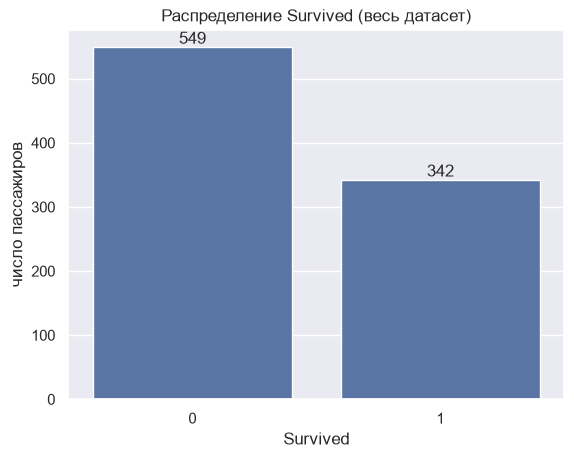

In [ ]:
counts = df[TARGET].value_counts().sort_index()
target_table = pd.DataFrame({"пассажиров": counts, "доля, %": counts / len(df) * 100})
target_table.index = ["0 - погиб", "1 - выжил"]
display(target_table.round(1))

ax = sns.countplot(x=df[TARGET])
ax.bar_label(ax.containers[0])
ax.set_title("Распределение Survived (весь датасет)")
ax.set_xlabel("Survived")
ax.set_ylabel("число пассажиров")
plt.show()

**Вывод:**
- Погибли 549 человек (62%), выжили 342 (38%). Классы неравные, хотя перекос небольшой.
- Модель, которая всем отвечает "погиб", угадает 62% ответов, но не найдёт ни одного выжившего. Поэтому главная метрика - F1 для выживших, а не Accuracy.
- При разбиении нужна стратификация, чтобы доля выживших в train и test была одинаковой.

### Итоги раздела 2
- `PassengerId`, `Name` и `Ticket` в модель не идут (идентификаторы), из имени возьмём только обращение.
- `Cabin` не используем: 77% пропусков.
- Пропуски `Age` и `Embarked` заполним, категории закодируем, для SVM и KNN выровняем масштаб - всё в разделе 6 и только по train.

## 3. Отбор и создание признаков

### 3.1. Что не используем и почему

| Столбец | Почему не используем |
|---|---|
| `PassengerId` | просто номер строки в файле: о пассажире ничего не говорит, зато позволяет запомнить конкретного человека |
| `Name` | у каждого своё - идентификатор. Берём из имени только обращение (`Title`) |
| `Ticket` | почти у каждого свой - тоже почти идентификатор. К тому же по общему билету модель могла бы "узнавать" семьи вместо общих закономерностей |
| `Cabin` | неизвестна у 687 из 891 (77%), восстановить не из чего. Есть и подозрение, что каюту чаще знали у выживших - проверим в разделе 5 |

In [ ]:
# PassengerId - номер строки в файле, считая с 1
print("PassengerId = номер строки + 1 у всех пассажиров:", (df["PassengerId"] == df.index + 1).all())

PassengerId = номер строки + 1 у всех пассажиров: True


`PassengerId` действительно просто номер строки.

### 3.2. Обращение (Title)
Обращение - это часть имени между запятой и точкой: "Braund, **Mr**. Owen Harris".

In [ ]:
raw_title = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False)  # текст между ", " и первой точкой
assert raw_title.notna().all()  # обращение нашлось у каждого пассажира
raw_title.value_counts()

Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

**Зачем нужен Title:** обращение сразу говорит о поле, возрасте и статусе. `Master` - мальчик, `Miss` - незамужняя женщина или девочка, `Mrs` - замужняя женщина, `Mr` - взрослый мужчина. Это полезно, потому что у 177 пассажиров нет возраста, а мальчика видно по `Master` и без него.

**Как объединяем:**
- `Mlle` - французское "мадемуазель", то же, что `Miss`; `Mme` - "мадам", то же, что `Mrs`; `Ms` (одна пассажирка) относим к `Miss`.
- Остальные (Dr, Rev, Col, Major, Capt, Sir, Lady, the Countess, Don, Jonkheer) - звания и титулы, их объединяем в `Rare`. У многих по одному человеку, а категория из одного человека - тот же идентификатор.
- Правило составлено по смыслу обращений, а не по данным, поэтому его можно применять до разбиения - утечки нет.

### 3.3. Размер семьи (FamilySize)
`FamilySize = SibSp + Parch + 1` (единица - сам пассажир).
- `SibSp` и `Parch` делят семью на две части, а на выживание, скорее всего, влияет общий размер: один, небольшая семья или большая. Проверим в разделе 5.
- `SibSp` и `Parch` тоже оставляем: в них разная информация (братья, сёстры, супруги - и родители, дети). Для SVM и KNN семья из-за этого учитывается трижды - в разделе 7 проверим, не мешает ли это.

### 3.4. Функция подготовки признаков

In [ ]:
TITLE_SYNONYMS = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
COMMON_TITLES = ["Mr", "Mrs", "Miss", "Master"]  # остальные обращения -> "Rare"
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Title", "FamilySize"]


def make_features(data: pd.DataFrame) -> pd.DataFrame:
    # Из таблицы в формате Kaggle делает 9 признаков модели.
    # Каждая строка обрабатывается отдельно, статистики по данным не считаются,
    # пропуски не заполняются (это сделает Pipeline в разделе 6).
    out = data[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
    title = data["Name"].str.extract(r",\s*([^.]+)\.", expand=False).replace(TITLE_SYNONYMS)
    out["Title"] = title.where(title.isin(COMMON_TITLES), "Rare")
    out["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    return out[FEATURES]


preview = make_features(df)
display(preview.head())
print("Title:", preview["Title"].value_counts().to_dict())
print("FamilySize:", preview["FamilySize"].value_counts().sort_index().to_dict())
print("Пропуски:", preview.isna().sum()[lambda s: s > 0].to_dict())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize
0,3,male,22.0,1,0,7.2500,S,Mr,2
1,1,female,38.0,1,0,71.2833,C,Mrs,2
2,3,female,26.0,0,0,7.9250,S,Miss,1
3,1,female,35.0,1,0,53.1000,S,Mrs,2
4,3,male,35.0,0,0,8.0500,S,Mr,1


Title: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}
FamilySize: {1: 537, 2: 161, 3: 102, 4: 29, 5: 15, 6: 22, 7: 12, 8: 6, 11: 7}
Пропуски: {'Age': 177, 'Embarked': 2}


**Вывод:**
- Получилось 9 признаков, ответа `Survived` среди них нет.
- Обращения: Mr - 517, Miss - 185, Mrs - 126, Master - 40, Rare - 23. Даже самая маленькая группа - 23 человека, так что `Title` не указывает на конкретного пассажира.
- 60% пассажиров (537) ехали одни.
- Пропуски `Age` и `Embarked` пока остались - их заполнит Pipeline в разделе 6.

## 4. Разбиение на train и test
Делим 80/20 со стратификацией по `Survived` и `random_state=42` - как в презентации к лабораторной. Test понадобится только в разделе 14.

In [ ]:
X = make_features(df)
y = df[TARGET]
assert TARGET not in X.columns  # целевая переменная не попала в признаки

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,  # доля выживших в train и test одинаковая
)
print(f"train: {len(X_train)} пассажиров ({len(X_train) / len(X):.0%})")
print(f"test:  {len(X_test)} пассажиров ({len(X_test) / len(X):.0%})")
print(f"признаков: {X.shape[1]}")

train: 712 пассажиров (80%)
test:  179 пассажиров (20%)
признаков: 9


**Почему 80/20:** 179 пассажиров в test хватает для оценки, хотя уже сейчас одна ошибка меняет Accuracy на полпроцента. Меньший test дал бы слишком случайную оценку, больший оставил бы модели меньше данных для обучения.

In [ ]:
# проверка стратификации: сколько погибших и выживших в каждой части
split_table = pd.DataFrame({
    "пассажиров": [len(y), len(y_train), len(y_test)],
    "погибших (0)": [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "выживших (1)": [y.sum(), y_train.sum(), y_test.sum()],
    "доля выживших, %": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["весь датасет", "train", "test"])
display(split_table.round(2))

# ни один пассажир не попал одновременно в train и test
assert X_train.index.intersection(X_test.index).empty
print("Пересечений между train и test нет.")

,пассажиров,погибших (0),выживших (1),"доля выживших, %"
весь датасет,891,549,342,38.38
train,712,439,273,38.34
test,179,110,69,38.55


Пересечений между train и test нет.


**Проверка:**
- Доля выживших в train и test одинаковая (38.3% и 38.6%), пересечений нет, ответа среди признаков нет.
- В test 110 погибших и 69 выживших - как в матрице ошибок из презентации к лабораторной (99 + 11 и 25 + 44). Значит, разбиение у нас то же, что в презентации, и результаты можно сравнивать со слайдами.
- Разбиение совпадает, хотя признаки у нас другие: кто попадёт в test, зависит только от числа строк, их порядка, ответа `y` и `random_state`. Поэтому строки до разбиения мы не удаляли и не переставляли.
- Дальше всё решаем только по train, а test впервые откроем в разделе 14.

## 5. Анализ данных (только train)
Смотрим, от чего зависит выживание, только на train (712 пассажиров), чтобы test не влиял на решения. На графиках - доля выживших в группе, в таблицах - сколько в группе людей: если группа маленькая, вывод по ней ненадёжен.

In [ ]:
train_df = X_train.assign(**{TARGET: y_train})  # копия train с целевой переменной - только для анализа


def survival_table(data, by):
    # число пассажиров и доля выживших (%) в каждой группе
    table = data.groupby(by, observed=True)[TARGET].agg(["count", "mean"])
    table.columns = ["пассажиров", "выжило, %"]
    table["выжило, %"] *= 100
    return table.round(1)

### 5.1. Пол и класс

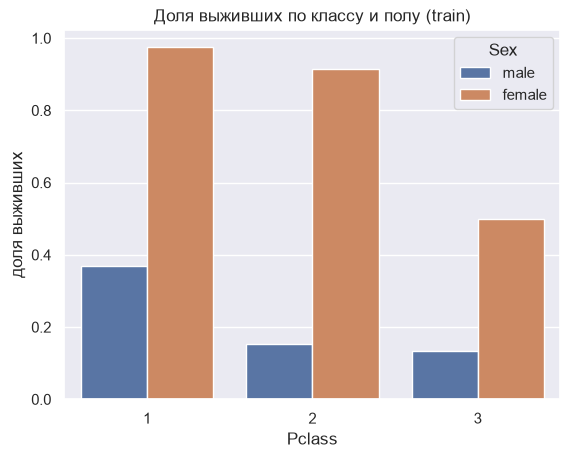

пассажиров           выжило, %            
Sex        female male  все    female  male   все
Pclass                                           
1              79   92  171      97.5  37.0  64.9
2              58   92  150      91.4  15.2  44.7
3             116  275  391      50.0  13.5  24.3
все           253  459  712      74.3  18.5  38.3

In [ ]:
ax = sns.barplot(data=train_df, x="Pclass", y=TARGET, hue="Sex", errorbar=None)
ax.set_title("Доля выживших по классу и полу (train)")
ax.set_ylabel("доля выживших")
plt.show()

# строки - класс, столбцы - пол; "все" - итог по строке или столбцу
sex_class = train_df.pivot_table(index="Pclass", columns="Sex", values=TARGET,
                                 aggfunc=["count", "mean"], margins=True, margins_name="все")
sex_class = sex_class.rename(columns={"count": "пассажиров", "mean": "выжило, %"}, level=0)
sex_class["выжило, %"] *= 100
sex_class.round(1)

**Вывод:**
- Главное - пол: выжили 74% женщин и только 19% мужчин. Класс тоже важен: в 1-м классе выжили 65%, в 3-м - 24%.
- Женщины 1-2 класса спаслись почти все, мужчины 2-3 класса почти все погибли - здесь модели будет легко.
- Трудно будет с женщинами 3-го класса (выжила ровно половина) и мужчинами 1-го класса (37%). Скорее всего, ошибок там будет больше всего.

### 5.2. Обращение

In [ ]:
title_table = survival_table(train_df, "Title")
title_table["без возраста, %"] = train_df["Age"].isna().groupby(train_df["Title"]).mean() * 100
title_table["медиана Age"] = train_df.groupby("Title")["Age"].median()
title_table.sort_values("выжило, %").round(1)

,пассажиров,"выжило, %","без возраста, %",медиана Age
Title,,,,
Mr,412,15.3,22.8,30.0
Rare,18,38.9,5.6,49.0
Master,31,54.8,9.7,3.0
Miss,144,70.8,18.1,22.0
Mrs,107,78.5,12.1,35.0


**Вывод:**
- `Title` различает мужчин: мальчики (`Master`, медианный возраст 3 года) выжили в 55% случаев, взрослые мужчины (`Mr`) - в 15%. По одному полу этого не видно.
- У женщин разница меньше: `Mrs` - 79%, `Miss` - 71%.
- Возраст чаще всего неизвестен у `Mr` и `Miss`, но мальчика модель узнает по `Master` и без возраста.
- В `Rare` всего 18 человек - по ним выводов не делаем.

### 5.3. Возраст

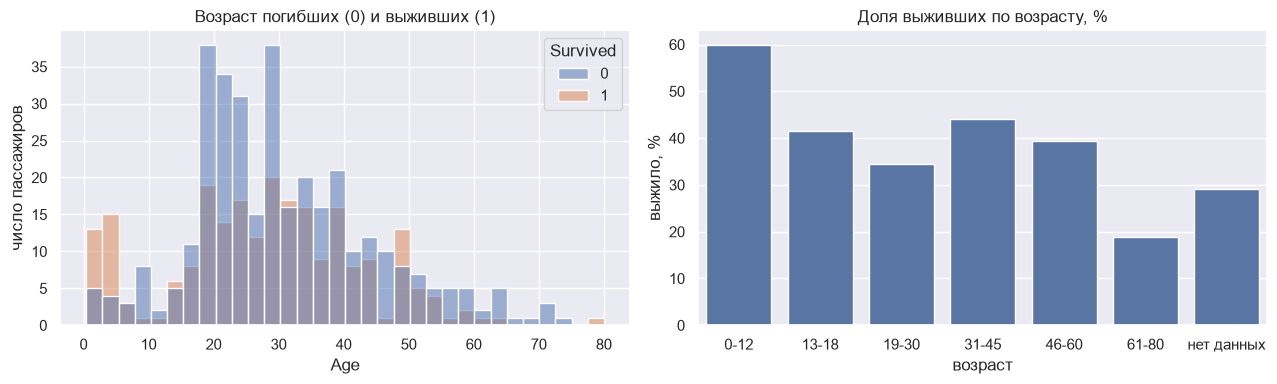

age_group,0-12,13-18,19-30,31-45,46-60,61-80,нет данных
пассажиров,55.0,53.0,215.0,170.0,66.0,16.0,137.0
"выжило, %",60.0,41.5,34.4,44.1,39.4,18.8,29.2


In [ ]:
# возрастные группы; пассажиры без возраста - отдельная группа
age_group = pd.cut(train_df["Age"], bins=[0, 12, 18, 30, 45, 60, 80],
                   labels=["0-12", "13-18", "19-30", "31-45", "46-60", "61-80"])
age_group = age_group.cat.add_categories("нет данных").fillna("нет данных")
age_table = survival_table(train_df.assign(age_group=age_group), "age_group")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=train_df, x="Age", hue=TARGET, bins=32, ax=axes[0])
axes[0].set_title("Возраст погибших (0) и выживших (1)")
axes[0].set_ylabel("число пассажиров")
sns.barplot(x=age_table.index, y=age_table["выжило, %"], ax=axes[1])
axes[1].set_title("Доля выживших по возрасту, %")
axes[1].set_xlabel("возраст")
plt.tight_layout()
plt.show()

age_table.T

**Вывод:**
- Чаще всех выживали дети до 12 лет (60%), реже всех - пожилые 61-80 лет (19%, но их всего 16). Между ними разница небольшая.
- Значит, возраст важен в основном для детей. Деревья такое найдут ("младше 12 или нет"), хотя корреляция возраста с выживанием почти нулевая (раздел 5.8).
- Среди тех, у кого возраст неизвестен, выжили только 29%: в основном это взрослые мужчины.

### 5.4. Стоимость билета

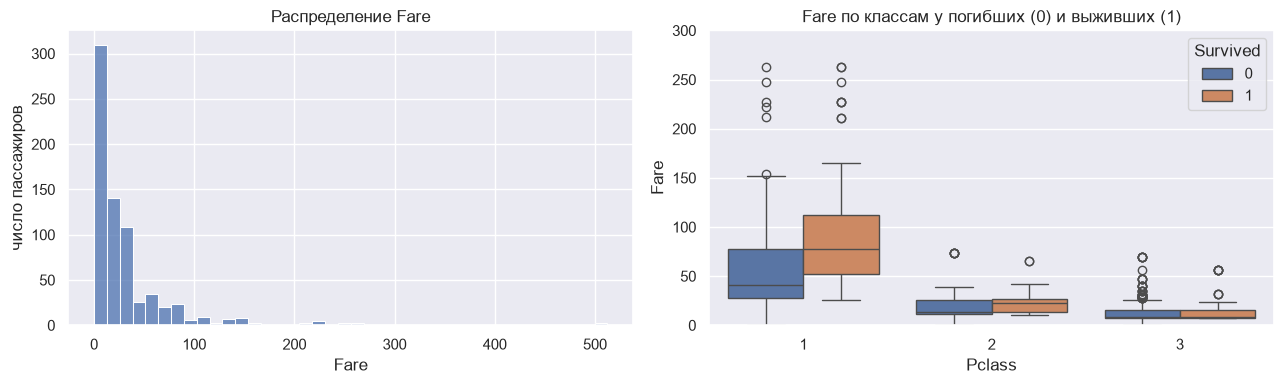

Асимметрия Fare (skew): 4.65
Билетов дороже 300: 2


,count,25%,50%,75%,max
Pclass,,,,,
1,171.0,30.7,58.0,100.0,512.3
2,150.0,13.0,14.5,26.0,73.5
3,391.0,7.8,8.0,15.5,69.6


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train_df["Fare"], bins=40, ax=axes[0])
axes[0].set_title("Распределение Fare")
axes[0].set_ylabel("число пассажиров")
sns.boxplot(data=train_df, x="Pclass", y="Fare", hue=TARGET, ax=axes[1])
axes[1].set_ylim(0, 300)  # несколько билетов дороже 300 не показаны, чтобы ящики не сжимались
axes[1].set_title("Fare по классам у погибших (0) и выживших (1)")
plt.tight_layout()
plt.show()

print(f"Асимметрия Fare (skew): {train_df['Fare'].skew():.2f}")
print(f"Билетов дороже 300: {(train_df['Fare'] > 300).sum()}")
train_df.groupby("Pclass")["Fare"].describe()[["count", "25%", "50%", "75%", "max"]].round(1)

**Вывод:**
- Большинство билетов дешевле 50, но есть единицы до 512. Это реальные цены, выбросы не удаляем.
- Цена сильно зависит от класса: медиана 58 в 1-м классе, 14.5 во 2-м, 8 в 3-м.
- Внутри 1-го класса выжившие платили больше, во 2-м и 3-м разницы почти нет.

### 5.5. Порт посадки

In [ ]:
embarked_table = survival_table(train_df, "Embarked")
embarked_table["женщин, %"] = (train_df["Sex"] == "female").groupby(train_df["Embarked"]).mean() * 100
# из каких классов пассажиры каждого порта, % по строке
class_mix = pd.crosstab(train_df["Embarked"], train_df["Pclass"], normalize="index") * 100
embarked_table.join(class_mix.add_prefix("класс ").add_suffix(", %")).round(1)

,пассажиров,"выжило, %","женщин, %","класс 1, %","класс 2, %","класс 3, %"
Embarked,,,,,,
C,139,56.1,45.3,53.2,8.6,38.1
Q,55,43.6,49.1,1.8,3.6,94.5
S,516,32.8,31.2,18.2,26.4,55.4


**Вывод:**
- Чаще всего выживали севшие в Шербуре (C, 56%), реже всего - в Саутгемптоне (S, 33%).
- Но в Шербуре больше половины пассажиров из 1-го класса, а в Саутгемптоне - меньше пятой части. Дело не в самом порту, а в том, кто в нём садился.
- В Квинстауне (Q) почти все из 3-го класса, но выжили 44% - зато там почти половина пассажиров женщины. Людей из Q всего 55, так что это осторожный вывод.

### 5.6. Размер семьи

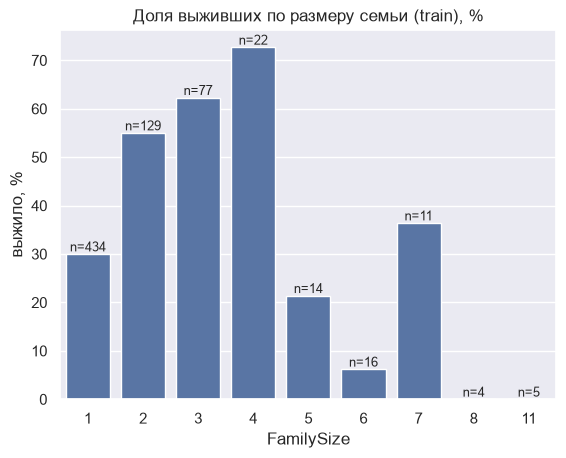

family_group,один,2-4,5 и больше
пассажиров,434.0,228.0,50.0
"выжило, %",30.0,59.2,16.0


In [ ]:
family_table = survival_table(train_df, "FamilySize")

ax = sns.barplot(x=family_table.index, y=family_table["выжило, %"])
ax.bar_label(ax.containers[0], labels=[f"n={n}" for n in family_table["пассажиров"]], fontsize=9)
ax.set_title("Доля выживших по размеру семьи (train), %")
ax.set_xlabel("FamilySize")
plt.show()

# то же, но крупными группами
family_group = pd.cut(train_df["FamilySize"], bins=[0, 1, 4, 11], labels=["один", "2-4", "5 и больше"])
survival_table(train_df.assign(family_group=family_group), "family_group").T

**Вывод:**
- Одиночки выжили в 30% случаев, семьи из 2-4 человек - в 59%, большие семьи (5 и больше) - в 16%.
- Зависимость похожа на горку: и одиночкам, и большим семьям хуже. Поэтому `FamilySize` полезен, хотя корреляция с выживанием почти нулевая: корреляция замечает только связь вида "чем больше, тем лучше (или хуже)".
- Для семей из 7, 8 и 11 человек данных мало (4-11 пассажиров), проценты там случайные.

### 5.7. Cabin: пропуски и гипотеза

In [ ]:
# исходный столбец Cabin для тех же пассажиров train (в признаки он не входит)
has_cabin = df.loc[X_train.index, "Cabin"].notna()
print(f"Cabin пропущен в train: {(~has_cabin).sum()} из {len(has_cabin)} ({(~has_cabin).mean():.1%})")
print(f"Cabin пропущен во всём датасете: {df['Cabin'].isna().sum()} из {len(df)} ({df['Cabin'].isna().mean():.1%})")

# доля выживших при известной и неизвестной каюте - отдельно внутри каждого класса
cabin_table = (train_df.assign(каюта=has_cabin.map({True: "известна", False: "неизвестна"}))
               .pivot_table(index="Pclass", columns="каюта", values=TARGET, aggfunc=["count", "mean"]))
cabin_table = cabin_table.rename(columns={"count": "пассажиров", "mean": "выжило, %"}, level=0)
cabin_table["выжило, %"] *= 100
cabin_table.round(1)

Cabin пропущен в train: 552 из 712 (77.5%)
Cabin пропущен во всём датасете: 687 из 891 (77.1%)


пассажиров            выжило, %           
каюта    известна неизвестна  известна неизвестна
Pclass                                           
1             136         35      69.9       45.7
2              15        135      80.0       40.7
3               9        382      55.6       23.6

**Главная причина не использовать Cabin:** номер каюты неизвестен у 552 из 712 пассажиров train (77.5%), а во всём датасете - у 687 из 891 (77.1%). Восстановить его не из чего.

**Проверка гипотезы "каюту чаще знали у выживших".** Заранее договорились: гипотеза подтверждается, если внутри каждого класса при известной каюте выживших заметно больше.
- Так и есть во всех трёх классах: 70% против 46% в 1-м, 80% против 41% во 2-м, 56% против 24% в 3-м. Значит, дело не только в том, что каюты известны в основном у 1-го класса.
- Но во 2-м и 3-м классах каюта известна всего у 15 и 9 человек, так что это подсказка, а не доказательство. И по данным нельзя понять, почему так: то ли каюты записывали со слов выживших, то ли эти каюты были ближе к шлюпкам.

**Решение:** не используем ни `Cabin`, ни флаг "каюта известна". В разделе 16 проверим, что бы он дал.

### 5.8. Корреляции числовых признаков

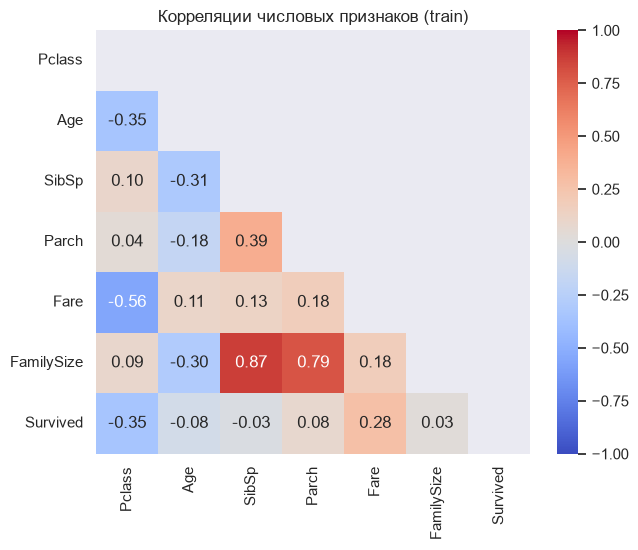

In [ ]:
num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", TARGET]
corr = train_df[num_cols].corr()  # Pearson; для Age - только пассажиры с известным возрастом
upper = np.triu(np.ones_like(corr, dtype=bool))  # верхний треугольник дублирует нижний

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, mask=upper, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title("Корреляции числовых признаков (train)")
plt.grid(False)
plt.show()

**Вывод:**
- `FamilySize` сильно связан с `SibSp` (0.87) и `Parch` (0.79) - он из них и сложен. Цена билета связана с классом (-0.56).
- С выживанием напрямую связаны только класс (-0.35) и цена билета (0.28). У возраста и размера семьи корреляция почти нулевая, хотя связь есть (разделы 5.3 и 5.6) - просто она не прямая.
- Пола здесь нет (он не число), но по разделу 5.1 это самый сильный признак.

### Итоги анализа
- Скорее всего, важнее всего будут пол и обращение, затем класс и цена билета, потом возраст (дети) и размер семьи. Порт - слабый признак, он работает через класс.
- Сложнее всего модели будет с женщинами 3-го класса и мужчинами 1-го класса.
- `Cabin` не используем. Для SVM и KNN нужно выровнять масштаб: цена билета в десятки раз крупнее остальных признаков.

## 6. Предобработка
Пропуски заполняем и категории кодируем внутри `Pipeline` - так всё, что для этого нужно (медиана, список категорий), считается только по train.

### 6.1. Числовые и категориальные признаки
- числовые: `Age`, `SibSp`, `Parch`, `Fare`, `FamilySize`;
- категориальные: `Pclass`, `Sex`, `Embarked`, `Title`.

`Pclass` считаем категорией: класс - это группа, а не количество. Если оставить число, для KNN и SVM 3-й класс оказался бы "вдвое дальше" от 1-го, чем 2-й, а смысла в этом нет.

### 6.2. Функция предобработки

In [ ]:
NUM_COLS = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
CAT_COLS = ["Pclass", "Sex", "Embarked", "Title"]


def make_preprocessor(scale, num_cols=NUM_COLS, cat_cols=CAT_COLS):
    # Заполнение пропусков и one-hot кодирование; scale=True добавляет StandardScaler
    # для числовых признаков (нужен SVM и KNN)
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    cat_steps = [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
    return ColumnTransformer(
        [
            ("num", Pipeline(num_steps), num_cols),
            ("cat", Pipeline(cat_steps), cat_cols),
        ],
        verbose_feature_names_out=False,  # имена столбцов без приставок: "Title_Mr", а не "cat__Title_Mr"
    )

| Шаг | Что делает | Почему |
|---|---|---|
| числа: `SimpleImputer(strategy="median")` | заполняет пропуски (у нас только `Age`) медианой | медиана не сдвигается из-за редких больших значений. Детей без возраста частично выручит `Title` |
| числа: `StandardScaler` (только для SVM и KNN) | приводит числовые признаки к одному масштабу | SVM и KNN считают расстояния, им масштаб важен. Столбцы 0/1 не трогаем |
| категории: `SimpleImputer(strategy="most_frequent")` | заполняет 2 пропуска `Embarked` самым частым портом | пропусков всего 2, самый частый порт - самый вероятный |
| категории: `OneHotEncoder(handle_unknown="ignore")` | превращает каждую категорию в отдельный столбец 0/1 | модели работают с числами. Если в новых данных попадётся незнакомая категория, ошибки не будет |

### 6.3. Что выучивает препроцессор
Для наглядности обучаем его отдельно на train. Модели получат свою копию внутри `Pipeline`.

In [ ]:
demo = make_preprocessor(scale=True).fit(X_train)  # обучается только на train
num_part = demo.named_transformers_["num"]
cat_part = demo.named_transformers_["cat"]

print("Значения для заполнения пропусков (по train):")
print("  числа, медиана:", dict(zip(NUM_COLS, num_part.named_steps["impute"].statistics_.round(4).tolist())))
print("  категории, самое частое:", dict(zip(CAT_COLS, cat_part.named_steps["impute"].statistics_)))
print("Категории one-hot:", {col: list(cats) for col, cats in zip(CAT_COLS, cat_part.named_steps["onehot"].categories_)})

scaler = num_part.named_steps["scale"]
display(pd.DataFrame({"среднее": scaler.mean_, "std": scaler.scale_}, index=NUM_COLS).round(3))

X_train_ready = pd.DataFrame(demo.transform(X_train), columns=demo.get_feature_names_out(), index=X_train.index)
assert not X_train_ready.isna().any().any()  # пропусков не осталось
print(f"До предобработки: {X_train.shape}, после: {X_train_ready.shape}")
X_train_ready.head(3).round(2)

Значения для заполнения пропусков (по train):
  числа, медиана: {'Age': 28.5, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 14.4542, 'FamilySize': 1.0}
  категории, самое частое: {'Pclass': 3, 'Sex': 'male', 'Embarked': 'S', 'Title': 'Mr'}
Категории one-hot: {'Pclass': [1, 2, 3], 'Sex': ['female', 'male'], 'Embarked': ['C', 'Q', 'S'], 'Title': ['Master', 'Miss', 'Mr', 'Mrs', 'Rare']}


,среднее,std
Age,29.556,13.016
SibSp,0.493,1.060
Parch,0.390,0.838
Fare,31.820,48.025
FamilySize,1.883,1.588


До предобработки: (712, 9), после: (712, 18)


,Age,SibSp,Parch,Fare,FamilySize,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
692,-0.08,-0.47,-0.47,0.51,-0.56,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
481,-0.08,-0.47,-0.47,-0.66,-0.56,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
527,-0.08,-0.47,-0.47,3.96,-0.56,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


**Вывод:**
- Пропуски возраста заполнятся числом 28.5 - медианой train. По всему датасету медиана была бы 28.0 (раздел 2.3), то есть test в расчёт не попал. Пропуски порта заполнятся значением S.
- Было 9 столбцов, стало 18: 5 числовых и 13 столбцов 0/1 (3 класса, 2 пола, 3 порта, 5 обращений).
- После масштабирования числа сопоставимы: например, `Fare` = 3.96 значит "цена на 4 стандартных отклонения выше средней".

### 6.4. Зачем Pipeline и кому нужно масштабирование
**Pipeline** соединяет предобработку и модель. Медиану, категории и масштаб он запоминает только по данным, на которых учится: в кросс-валидации - по обучающим фолдам, в конце - по train. К проверочным данным и к test всё это только применяется. Если бы мы заполнили пропуски по всему датасету, в медиану попал бы test - это была бы утечка.

**Кому нужно масштабирование:**

| Модель | Нужно? | Почему |
|---|---|---|
| дерево, лес, бустинг | нет | они задают вопросы вида "Fare > 50?", а ответ на такой вопрос не зависит от масштаба |
| SVM | да | сравнивает пассажиров по расстоянию, и без масштабирования его почти целиком задавала бы цена билета |
| KNN | да, обязательно | ищет ближайших соседей по расстоянию: разница в цене на 50 весила бы как разница в возрасте на 50 лет |

Проверим это на цифрах в разделах 12 и 13.

## 7. Метрики и схема эксперимента

### 7.1. Метрики
Матрица ошибок (строки - что было на самом деле, столбцы - что сказала модель; класс 1 - "выжил"):

| | прогноз 0 (погиб) | прогноз 1 (выжил) |
|---|---|---|
| **факт 0 (погиб)** | TN | FP |
| **факт 1 (выжил)** | FN | TP |

- **FP** (ложное срабатывание) - модель сказала "выжил", а человек погиб.
- **FN** (пропуск) - модель сказала "погиб", а человек выжил.

В нашей задаче обе ошибки одинаково плохи, и F1 учитывает обе.

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \qquad \text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Accuracy** - доля всех верных ответов. Модель "все погибли" уже даёт 0.62, поэтому одна Accuracy мало что говорит.
- **Precision** - из тех, кого модель назвала выжившими, сколько правда выжили.
- **Recall** - скольких выживших модель нашла.
- **F1** - объединяет Precision и Recall в одно число, это главная метрика ТЗ. Верно угаданных погибших она не учитывает - только то, как модель находит выживших.
- **ROC-AUC** (справочно) - насколько хорошо модель расставляет пассажиров по шансам выжить: 0.5 - как наугад, 1 - идеально. От порога не зависит.

In [ ]:
# почему F1 - гармоническое, а не обычное среднее
for p, r in [(0.8, 0.8), (1.0, 0.1)]:
    print(f"Precision = {p}, Recall = {r}:  обычное среднее = {(p + r) / 2:.2f},  F1 = {2 * p * r / (p + r):.2f}")

Precision = 0.8, Recall = 0.8:  обычное среднее = 0.80,  F1 = 0.80
Precision = 1.0, Recall = 0.1:  обычное среднее = 0.55,  F1 = 0.18


F1 - не обычное среднее: если одна из метрик плохая, F1 тоже будет низким. При Precision 1.0 и Recall 0.1 обычное среднее 0.55, а F1 - 0.18: модель нашла всего 10% выживших, и F1 это показывает.

### 7.2. Схема эксперимента

In [ ]:
# одни и те же 5 фолдов для всех моделей: random_state фиксирован, поэтому разбиение одинаковое при каждом вызове
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),  # если модель ни разу не сказала "1" - считаем 0
    "Recall": "recall",
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc",  # по predict_proba, а если его нет (SVC) - по decision_function
}
cv_results = {}  # средние метрики CV каждой модели
cv_fold_f1 = {}  # F1 каждой модели на каждом из 5 фолдов


def run_cv(name, model):
    # Кросс-валидация модели на train: среднее метрик по 5 фолдам, разброс F1 и F1 на обучающих фолдах
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    summary = {"train F1": res["train_F1"].mean()}
    summary.update({f"CV {m}": res[f"test_{m}"].mean() for m in SCORING})
    summary["CV F1 std"] = res["test_F1"].std()
    cv_results[name] = summary
    cv_fold_f1[name] = res["test_F1"]
    return pd.DataFrame(summary, index=[name]).round(4)


def metrics_on(model, X, y):
    # Все метрики уже обученной модели на выборке (X, y) - понадобится в разделе 14
    pred = model.predict(X)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X)[:, 1]  # вероятность класса 1
    else:
        score = model.decision_function(X)    # SVC без probability=True: расстояние до границы со знаком
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, score),
    }

- Все решения (набор признаков, глубина дерева, k, лучшая модель) принимаем по кросс-валидации на train: 5 раз учимся на 4/5 train и проверяемся на оставшейся 1/5.
- Эти пятые части (фолды) одинаковые для всех моделей, и в каждой та же доля выживших (`StratifiedKFold`) - сравнение честное.
- `train F1` - качество на тех данных, на которых модель училась. Если оно намного выше `CV F1`, модель переобучилась.
- `zero_division=0` нужен для baseline: он ни разу не говорит "выжил", и Precision получается 0/0 - считаем это нулём.
- Test - один раз, в разделе 14.

### 7.3. Проверка набора признаков
Сравниваем три набора:
- **A** - 7 исходных признаков;
- **B** - наш: A + `Title` + `FamilySize`;
- **C** - B без `SibSp` и `Parch` (проверяем, не мешает ли SVM и KNN, что семья учитывается трижды).

Проверяем на лесе, бустинге и SVM - их параметры фиксируем здесь, до проверки, - и на KNN с k = 5 (стандартное значение). Дерево не берём: его глубина ещё не выбрана.

**Правило (решили заранее):** оставляем B, если другой набор не лучше него заметнее, чем результаты обычно скачут от фолда к фолду.

In [ ]:
# модели с параметрами, зафиксированными заранее (они же - в разделах 10-12)
rf_model = RandomForestClassifier(
    n_estimators=300,     # число деревьев, как в Lab1
    min_samples_leaf=2,   # в листе минимум 2 пассажира - дерево не запоминает одиночные случаи
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
gb_model = GradientBoostingClassifier(
    n_estimators=200,     # как в Lab1: много маленьких шагов
    learning_rate=0.05,
    max_depth=3,          # неглубокие деревья
    random_state=RANDOM_STATE,
)
svm_model = SVC(C=1.0, kernel="rbf", gamma="scale")  # стандартные значения sklearn, записаны явно

FEATURE_SETS = {  # (числовые, категориальные)
    "A: 7 исходных": (["Age", "SibSp", "Parch", "Fare"], ["Pclass", "Sex", "Embarked"]),
    "B: + Title, FamilySize": (NUM_COLS, CAT_COLS),
    "C: B без SibSp, Parch": (["Age", "Fare", "FamilySize"], CAT_COLS),
}
check_models = {  # (модель, нужен ли scaler)
    "Random Forest": (rf_model, False),
    "Gradient Boosting": (gb_model, False),
    "SVM": (svm_model, True),
    "KNN (k=5)": (KNeighborsClassifier(n_neighbors=5), True),
}

f1_mean, f1_std = {}, {}
for set_name, (num_cols, cat_cols) in FEATURE_SETS.items():
    f1_mean[set_name], f1_std[set_name] = {}, {}
    for model_name, (model, scale) in check_models.items():
        pipe = Pipeline([("prep", make_preprocessor(scale, num_cols, cat_cols)), ("model", model)])
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1")["test_score"]  # те же 5 фолдов
        f1_mean[set_name][model_name] = scores.mean()
        f1_std[set_name][model_name] = scores.std()

feature_check = pd.DataFrame(f1_mean).T
feature_check["среднее по моделям"] = feature_check.mean(axis=1)
display(feature_check.round(4))

noise = pd.DataFrame(f1_std).T.loc["B: + Title, FamilySize"].mean()  # типичный разброс F1 между фолдами
base_b = feature_check.loc["B: + Title, FamilySize", "среднее по моделям"]
print(f"Типичный разброс CV F1 между фолдами (std, набор B): {noise:.4f}")
for set_name in ["A: 7 исходных", "C: B без SibSp, Parch"]:
    diff = feature_check.loc[set_name, "среднее по моделям"] - base_b
    print(f"{set_name}: отличие от B по среднему CV F1 = {diff:+.4f}")

,Random Forest,Gradient Boosting,SVM,KNN (k=5),среднее по моделям
A: 7 исходных,0.7448,0.7521,0.7447,0.7190,0.7402
"B: + Title, FamilySize",0.7601,0.7441,0.7528,0.7263,0.7459
"C: B без SibSp, Parch",0.7592,0.7468,0.7571,0.7399,0.7508


Типичный разброс CV F1 между фолдами (std, набор B): 0.0289
A: 7 исходных: отличие от B по среднему CV F1 = -0.0057
C: B без SibSp, Parch: отличие от B по среднему CV F1 = +0.0049


**Вывод:**
- Средний CV F1: A - 0.740, B - 0.746, C - 0.751. Наборы отличаются меньше чем на 0.011, а результаты от фолда к фолду скачут примерно на 0.029. По качеству наборы практически одинаковые.
- По правилу оставляем **B**.
- Честно: `Title` и `FamilySize` почти не повышают качество. Оставляем их, потому что они осмысленные (раздел 5) и не ухудшают результат. Для KNN набор C немного лучше (0.740 против 0.726) - похоже, тройной учёт семьи ему чуть мешает, но и это в пределах случайности.

## 8. Baseline
Baseline всегда отвечает самым частым классом и не смотрит на пассажира. Это нижняя планка: любая модель должна быть заметно лучше.

In [ ]:
baseline = DummyClassifier(strategy="most_frequent")  # всегда отвечает самым частым классом train
display(run_cv("Baseline (most_frequent)", baseline))

baseline.fit(X_train, y_train)
print(f"Baseline всегда отвечает: {baseline.predict(X_train.iloc[:1])[0]} "
      f"(в train погибших {(y_train == 0).sum()} из {len(y_train)}, {(y_train == 0).mean():.1%})")

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
Baseline (most_frequent),0.0,0.6166,0.0,0.0,0.0,0.5,0.0


Baseline всегда отвечает: 0 (в train погибших 439 из 712, 61.7%)


**Вывод:** baseline всем отвечает "погиб" (таких в train 62%). Поэтому Accuracy у него 0.62, а F1 - 0: ни одного выжившего он не нашёл. ROC-AUC 0.5 - как наугад.

## 9. Decision Tree
Дерево задаёт цепочку вопросов по одному признаку ("Mr?", "3-й класс?") и в конце отвечает большинством. Вопрос выбирается так, чтобы после него группы стали "чище" - в идеале в каждой только выжившие или только погибшие. Чистоту меряет Gini: $1 - p_0^2 - p_1^2$, где $p_0$ и $p_1$ - доли погибших и выживших; 0 - группа чистая, 0.5 - пополам.

Масштабирование дереву не нужно. Без ограничений оно растёт, пока не разделит всех пассажиров, то есть заучивает train, поэтому глубину ограничиваем.

### 9.1. Выбор глубины по CV на train
Пробуем глубину от 1 до 10 и без ограничения, берём ту, у которой лучший CV F1 (при равенстве - меньшую).

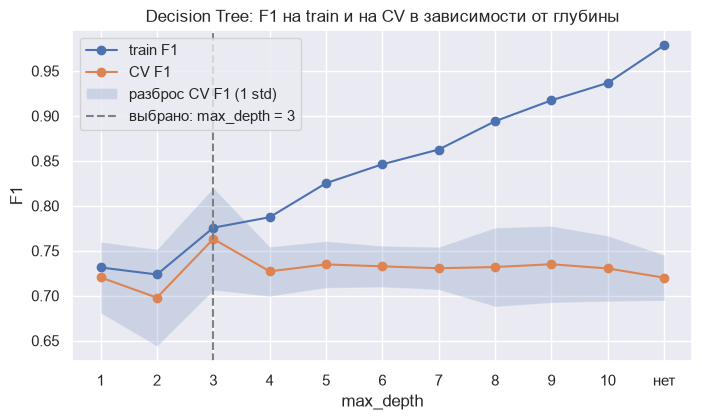

max_depth,1,2,3,4,5,6,7,8,9,10,нет
train F1,0.7314,0.7236,0.7756,0.7873,0.8252,0.8462,0.8626,0.8941,0.9173,0.9367,0.9786
CV F1,0.7204,0.6979,0.7632,0.7271,0.7348,0.7327,0.7306,0.7319,0.7350,0.7303,0.7200
CV F1 std,0.0397,0.0540,0.0571,0.0276,0.0260,0.0230,0.0238,0.0440,0.0427,0.0365,0.0254


In [ ]:
tree_pipe = Pipeline([
    ("prep", make_preprocessor(scale=False)),  # деревьям масштабирование не нужно
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
depth_grid = list(range(1, 11)) + [None]  # None - без ограничения глубины
tree_search = GridSearchCV(
    tree_pipe,
    param_grid={"model__max_depth": depth_grid},
    scoring=SCORING["F1"],
    cv=cv,                    # те же 5 фолдов, что у всех моделей
    return_train_score=True,
)
tree_search.fit(X_train, y_train)  # при равных CV F1 выбирается первая (меньшая) глубина
best_depth = tree_search.best_params_["model__max_depth"]

depth_res = pd.DataFrame({
    "max_depth": ["нет" if d is None else d for d in depth_grid],
    "train F1": tree_search.cv_results_["mean_train_score"],
    "CV F1": tree_search.cv_results_["mean_test_score"],
    "CV F1 std": tree_search.cv_results_["std_test_score"],
}).set_index("max_depth")

x = np.arange(len(depth_grid))
plt.figure(figsize=(8, 4.3))
plt.plot(x, depth_res["train F1"], marker="o", label="train F1")
plt.plot(x, depth_res["CV F1"], marker="o", label="CV F1")
plt.fill_between(x, depth_res["CV F1"] - depth_res["CV F1 std"], depth_res["CV F1"] + depth_res["CV F1 std"],
                 alpha=0.2, label="разброс CV F1 (1 std)")
plt.axvline(depth_grid.index(best_depth), color="gray", linestyle="--", label=f"выбрано: max_depth = {best_depth}")
plt.xticks(x, depth_res.index)
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Decision Tree: F1 на train и на CV в зависимости от глубины")
plt.legend()
plt.show()

depth_res.round(4).T

**Вывод:**
- Чем глубже дерево, тем лучше оно угадывает train: без ограничения почти идеально (0.98). А на CV качество после глубины 3 не растёт (0.72-0.74). Дерево просто заучивает обучающих пассажиров - это и есть переобучение.
- Лучше всего на CV глубина 3 (F1 0.763). Соседние глубины ненамного хуже, так что этот выбор отчасти случайный.
- Даже один вопрос "Mr или нет" уже даёт F1 0.72.

### 9.2. Выбранное дерево

In [ ]:
tree = tree_search.best_estimator_  # Pipeline с лучшей глубиной, GridSearchCV уже обучил его на всём train
display(run_cv("Decision Tree", tree))

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
Decision Tree,0.7756,0.8287,0.8097,0.729,0.7632,0.8584,0.0571


**Вывод:** дерево глубины 3 находит 73% выживших, и 81% его ответов "выжил" верны (CV F1 0.763). На train и на CV качество почти одинаковое (0.776 и 0.763) - переобучения нет.

### 9.3. Схема дерева

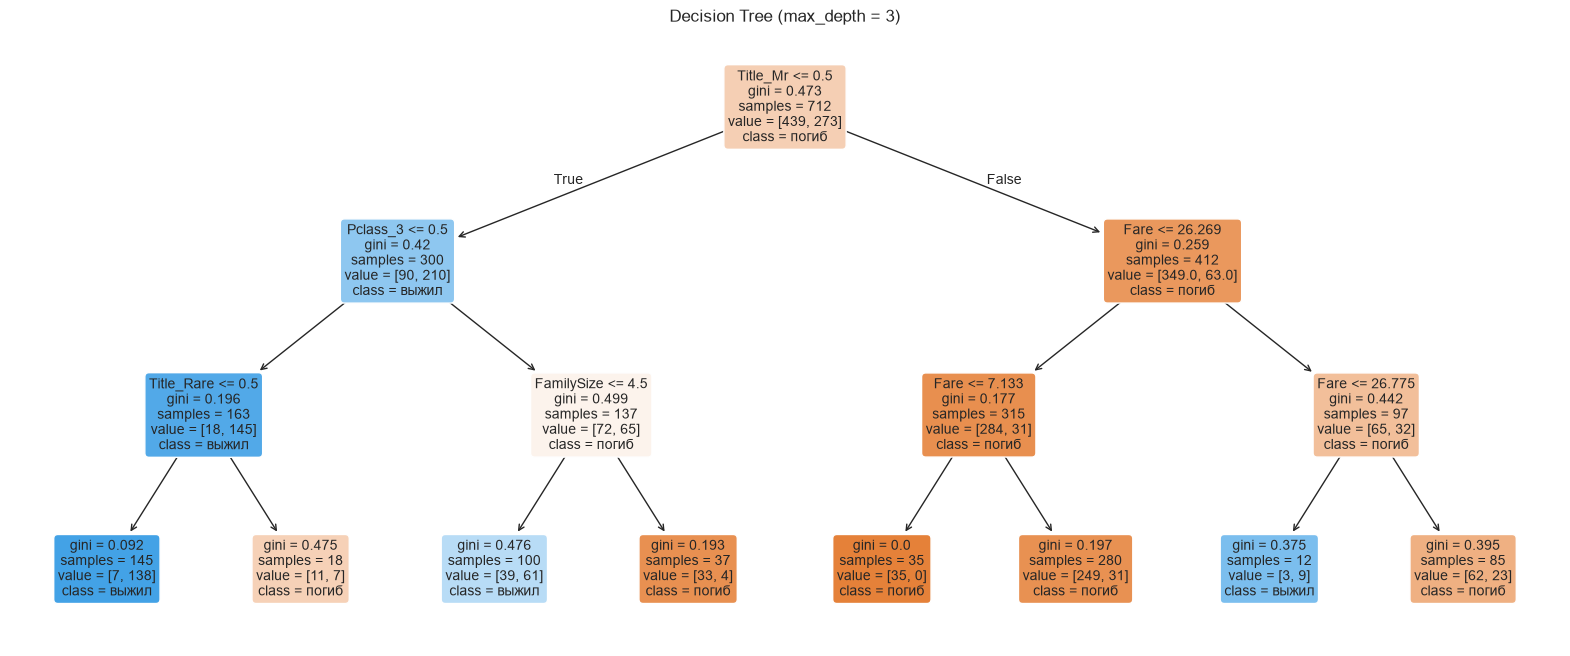

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(
    tree.named_steps["model"],
    feature_names=tree.named_steps["prep"].get_feature_names_out(),
    class_names=["погиб", "выжил"],
    filled=True,    # цвет узла - преобладающий класс, насыщенность - насколько он преобладает
    rounded=True,
    max_depth=3,    # если дерево глубже, показываем только верхние 3 уровня
    fontsize=10,
)
plt.title(f"Decision Tree (max_depth = {best_depth})")
plt.show()

**Как читать:** в каждом прямоугольнике - вопрос; `samples` - сколько пассажиров дошло до этого места; `value` - [погибших, выживших]; `class` - ответ. Влево идут те, для кого ответ на вопрос "да". `Title_Mr <= 0.5` означает "не Mr".

- **Первый вопрос - "Mr или нет".** Среди не-Mr (женщины, мальчики) выжили 210 из 300, среди Mr - только 63 из 412.
- **Не Mr из 1-2 класса** почти все выжили (138 из 145).
- **Не Mr из 3-го класса** - трудная группа. Тут дерево смотрит на размер семьи: до 4 человек - "выжил", в больших семьях почти все погибли.
- **Mr** - почти везде "погиб". Исключение - 12 мужчин с ценой билета от 26.27 до 26.78. Такой узкий интервал цены больше похож на заучивание конкретных пассажиров, чем на закономерность.

### 9.4. Feature importance (MDI)
Важность признака (MDI) показывает, насколько вопросы по этому признаку сделали группы "чище". Сумма важностей всех признаков равна 1.

После one-hot у нас 18 столбцов, поэтому складываем их обратно по исходным признакам: например, `Title` = `Title_Mr` + `Title_Miss` + ...

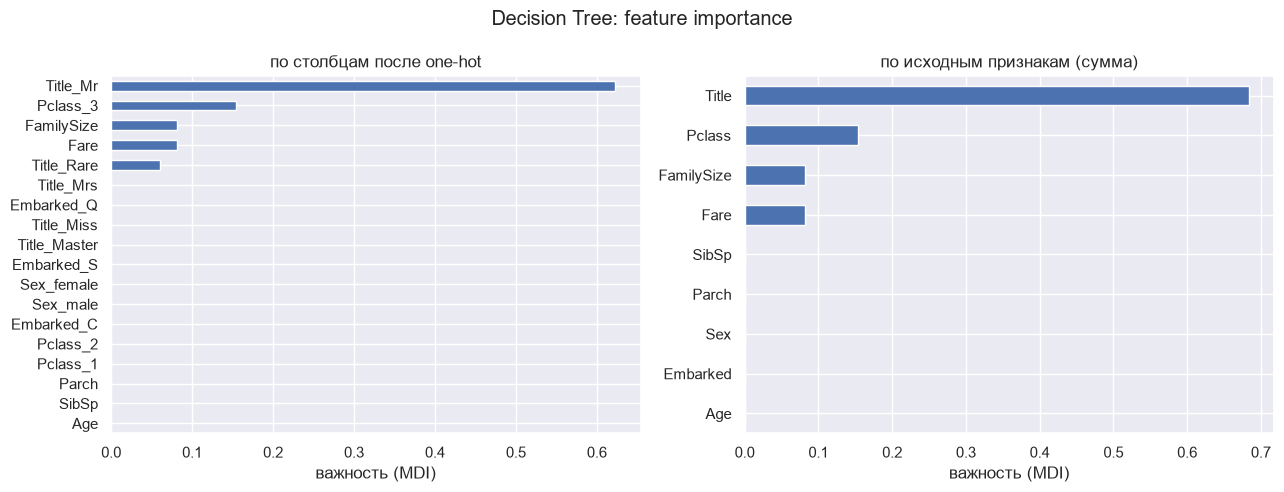

Title         0.6835
Pclass        0.1537
FamilySize    0.0815
Fare          0.0812
Age           0.0000
Parch         0.0000
Embarked      0.0000
Sex           0.0000
SibSp         0.0000
dtype: float64

In [ ]:
def importance_by_feature(model):
    # MDI-важность обученного Pipeline: по столбцам после one-hot и суммой по исходным признакам
    names = model.named_steps["prep"].get_feature_names_out()
    by_column = pd.Series(model.named_steps["model"].feature_importances_, index=names)
    # "Title_Mr" -> "Title": у исходных признаков нет "_" в имени, поэтому берём часть до "_"
    by_feature = by_column.groupby(lambda name: name.split("_")[0]).sum()
    return by_column, by_feature


tree_imp_col, tree_imp = importance_by_feature(tree)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tree_imp_col.sort_values().plot.barh(ax=axes[0], title="по столбцам после one-hot")
tree_imp.sort_values().plot.barh(ax=axes[1], title="по исходным признакам (сумма)")
for ax in axes:
    ax.set_xlabel("важность (MDI)")
plt.suptitle("Decision Tree: feature importance")
plt.tight_layout()
plt.show()

tree_imp.sort_values(ascending=False).round(4)

**Вывод:**
- Почти вся важность (68%) - у `Title`, точнее у вопроса "Mr или нет". Дальше класс (0.15), размер семьи и цена билета (по 0.08).
- У пола, возраста и порта - ноль: дерево с 7 вопросами про них не спрашивает. Но это не значит, что пол не важен: `Title_Mr` уже почти совпадает с "мужчина" и вдобавок отделяет мальчиков.
- Это совпадает с анализом данных: главное - пол (через обращение) и класс.

## 10. Random Forest
Случайный лес - это 300 деревьев, и все немного разные:
- каждое учится на своей случайной выборке пассажиров из train (с повторами);
- в каждом узле выбирает вопрос не из всех столбцов, а из 4 случайных;
- ответ леса - голосование всех деревьев.

Каждое дерево по отдельности переобучено, но ошибаются они по-разному, и при голосовании ошибки гасятся. Масштабирование не нужно. Параметры заданы в разделе 7.3 (300 деревьев, в листе минимум 2 пассажира).

### 10.1. Качество по CV

In [ ]:
rf = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", rf_model),  # параметры зафиксированы в разделе 7.3
])
run_cv("Random Forest", rf)
rf.fit(X_train, y_train)  # финальное обучение на всём train - для раздела 14

pd.DataFrame(cv_results).T.loc[["Decision Tree", "Random Forest"]].round(4)

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
Decision Tree,0.7756,0.8287,0.8097,0.7290,0.7632,0.8584,0.0571
Random Forest,0.8778,0.8259,0.8109,0.7178,0.7601,0.8816,0.0244


**Вывод:**
- По F1 лес на уровне дерева (0.760 и 0.763) - разница случайная.
- Зато лес вдвое стабильнее: его результат от фолда к фолду скачет на 0.024, а у дерева - на 0.057. Это и есть польза от голосования многих деревьев.
- На train лес намного лучше (0.878): деревья запоминают обучающих пассажиров. Но на новых данных он не хуже дерева, так что вреда от этого нет. Лес оцениваем по CV, а не по train.

### 10.2. Feature importance (MDI) и сравнение с деревом

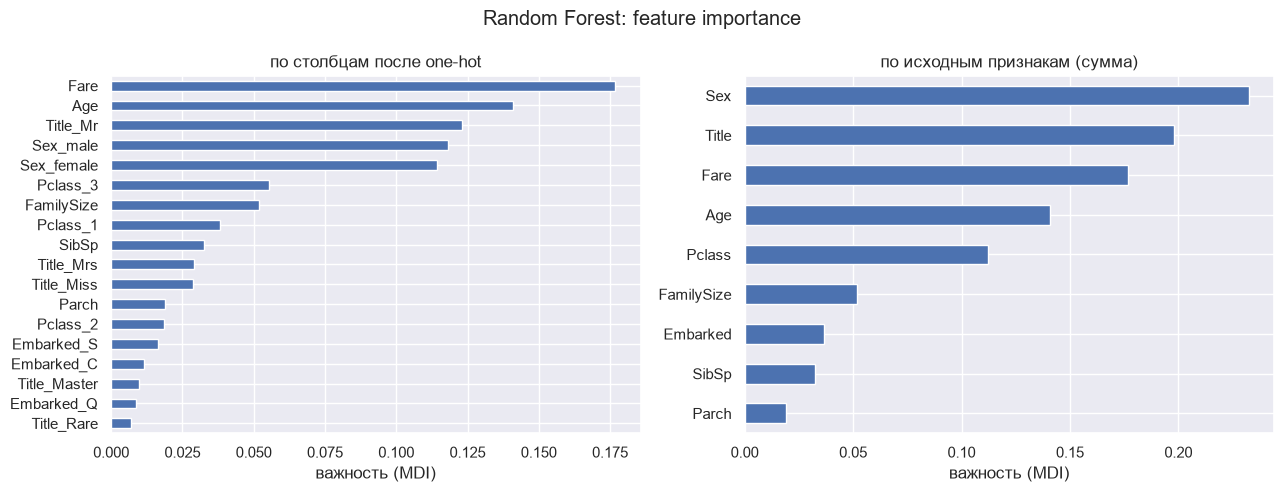

,DT важность,RF важность,DT место,RF место
Sex,0.0000,0.2325,5,1
Title,0.6835,0.1978,1,2
Fare,0.0812,0.1768,4,3
Age,0.0000,0.1408,5,4
Pclass,0.1537,0.1123,2,5
FamilySize,0.0815,0.0518,3,6
Embarked,0.0000,0.0364,5,7
SibSp,0.0000,0.0324,5,8
Parch,0.0000,0.0190,5,9


In [ ]:
rf_imp_col, rf_imp = importance_by_feature(rf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rf_imp_col.sort_values().plot.barh(ax=axes[0], title="по столбцам после one-hot")
rf_imp.sort_values().plot.barh(ax=axes[1], title="по исходным признакам (сумма)")
for ax in axes:
    ax.set_xlabel("важность (MDI)")
plt.suptitle("Random Forest: feature importance")
plt.tight_layout()
plt.show()

# место 1 - самый важный; у признаков с нулевой важностью одинаковое место
pd.DataFrame({
    "DT важность": tree_imp,
    "RF важность": rf_imp,
    "DT место": tree_imp.rank(ascending=False, method="min").astype(int),
    "RF место": rf_imp.rank(ascending=False, method="min").astype(int),
}).sort_values("RF важность", ascending=False).round(4)

**Вывод:**
- Лес распределяет важность шире, чем дерево. Первые места у пола (0.23) и обращения (0.20): лесу в каждом узле доступны только 4 случайных столбца, и когда среди них нет `Title_Mr`, он спрашивает про пол.
- Высоко стоят цена билета и возраст (0.18 и 0.14). Но MDI известна тем, что завышает признаки с большим числом разных значений - проверим другим способом в разделе 15.
- Общее с деревом: в первой пятёрке пол или обращение, класс и цена билета.

## 11. Gradient Boosting
Бустинг строит деревья по очереди: каждое новое неглубокое дерево (глубина 3) исправляет ошибки всех предыдущих. Вклад каждого дерева небольшой (`learning_rate=0.05`), всего 200 деревьев. Параметры заданы в разделе 7.3.

| | Random Forest | Gradient Boosting |
|---|---|---|
| как строятся деревья | независимо, потом голосуют | по очереди, каждое исправляет предыдущие |
| деревья | глубокие | неглубокие |
| риск переобучения | небольшой | растёт, если деревьев много или шаг большой |

### 11.1. Качество по CV и сравнение с лесом

In [ ]:
gb = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", gb_model),  # параметры зафиксированы в разделе 7.3
])
run_cv("Gradient Boosting", gb)
gb.fit(X_train, y_train)  # финальное обучение на всём train - для раздела 14

display(pd.DataFrame(cv_results).T.loc[["Random Forest", "Gradient Boosting"]].round(4))

# попарное сравнение на одних и тех же 5 фолдах
folds = pd.DataFrame({name: cv_fold_f1[name] for name in ["Random Forest", "Gradient Boosting"]},
                     index=[f"фолд {i + 1}" for i in range(N_FOLDS)])
folds["RF - GB"] = folds["Random Forest"] - folds["Gradient Boosting"]
display(folds.T.round(4))
print(f"Random Forest лучше на {(folds['RF - GB'] > 0).sum()} фолдах из {N_FOLDS}")

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
Random Forest,0.8778,0.8259,0.8109,0.7178,0.7601,0.8816,0.0244
Gradient Boosting,0.8922,0.8146,0.7924,0.7032,0.7441,0.8904,0.0366


,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5
Random Forest,0.7810,0.7207,0.7800,0.7767,0.7423
Gradient Boosting,0.7963,0.7170,0.7475,0.6923,0.7677
RF - GB,-0.0153,0.0037,0.0325,0.0844,-0.0254


Random Forest лучше на 3 фолдах из 5


**Вывод:**
- CV F1 бустинга 0.744, у леса 0.760. Но на одних и тех же фолдах лес лучше только в 3 случаях из 5 - по F1 модели практически равны.
- Бустинг лучше всех расставляет пассажиров по шансам (ROC-AUC 0.890), но при пороге 0.5 реже говорит "выжил", поэтому его F1 ниже.
- На train у бустинга 0.892 - он сильнее всех подстраивается под обучающих пассажиров, хотя на CV это пока не вредит.

### 11.2. Feature importance (MDI) и сравнение с лесом

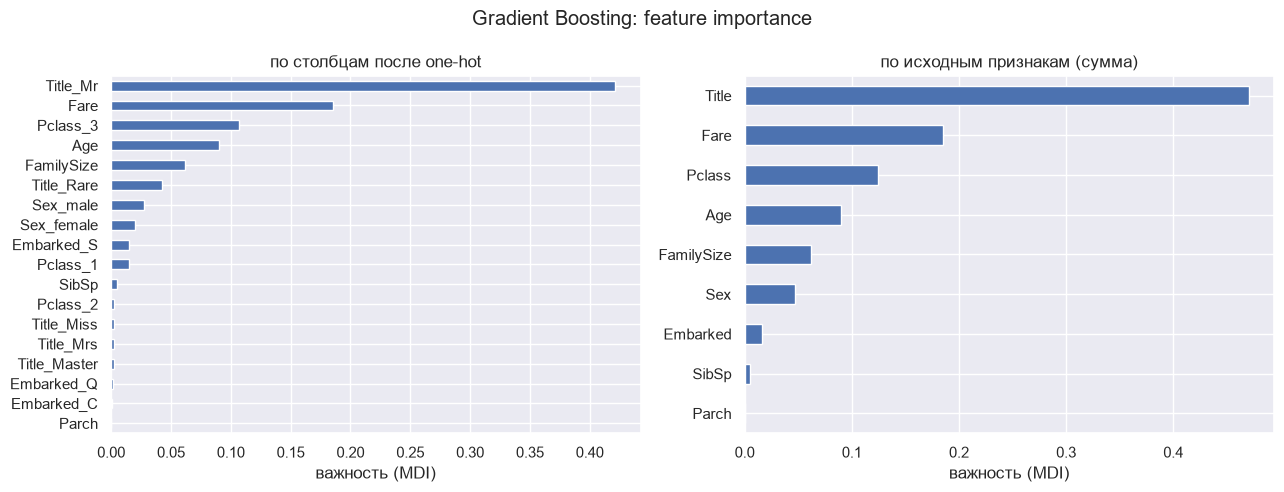

,RF важность,GB важность,RF место,GB место
Title,0.1978,0.4705,2,1
Fare,0.1768,0.1854,3,2
Pclass,0.1123,0.1242,5,3
Age,0.1408,0.0902,4,4
FamilySize,0.0518,0.0617,6,5
Sex,0.2325,0.0471,1,6
Embarked,0.0364,0.0165,7,7
SibSp,0.0324,0.0045,8,8
Parch,0.0190,0.0000,9,9


In [ ]:
gb_imp_col, gb_imp = importance_by_feature(gb)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
gb_imp_col.sort_values().plot.barh(ax=axes[0], title="по столбцам после one-hot")
gb_imp.sort_values().plot.barh(ax=axes[1], title="по исходным признакам (сумма)")
for ax in axes:
    ax.set_xlabel("важность (MDI)")
plt.suptitle("Gradient Boosting: feature importance")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "RF важность": rf_imp,
    "GB важность": gb_imp,
    "RF место": rf_imp.rank(ascending=False, method="min").astype(int),
    "GB место": gb_imp.rank(ascending=False, method="min").astype(int),
}).sort_values("GB важность", ascending=False).round(4)

**Вывод:**
- Бустинг, как и дерево, почти половину важности отдаёт `Title` (0.47): его деревья тоже первым делом спрашивают "Mr или нет", и пол после этого почти ничего не добавляет.
- Дальше - цена билета, класс и возраст. Родственники и порт - в конце.
- Если сложить пол и обращение (по сути это одно и то же), у всех трёх моделей это главный признак.

## 12. SVM (метод опорных векторов)
SVM ищет границу между выжившими и погибшими так, чтобы она проходила как можно дальше от ближайших пассажиров обоих классов. Эти ближайшие пассажиры называются опорными векторами - только они определяют границу.
- **C** - насколько сильно штрафовать пассажиров, оказавшихся не на своей стороне. Большой C подгоняет границу под train. У нас C = 1.
- **Ядро RBF** позволяет границе быть кривой: оно считает пассажиров похожими, если расстояние между ними маленькое ($e^{-\gamma \lVert x - z \rVert^2}$).
- Параметры заданы в разделе 7.3.

### 12.1. Со scaler и без

In [ ]:
svm_no_scale = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", SVC(C=1.0, kernel="rbf", gamma="scale")),  # те же параметры, что у svm_model
])
svm = Pipeline([
    ("prep", make_preprocessor(scale=True)),
    ("model", svm_model),  # параметры зафиксированы в разделе 7.3
])
run_cv("SVM без масштабирования", svm_no_scale)
run_cv("SVM", svm)
svm.fit(X_train, y_train)  # финальное обучение на всём train - для раздела 14

pd.DataFrame(cv_results).T.loc[["SVM без масштабирования", "SVM"]].round(4)

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
SVM без масштабирования,0.4665,0.6896,0.7032,0.3298,0.4464,0.7609,0.0547
SVM,0.7868,0.8230,0.8089,0.7067,0.7528,0.8570,0.0311


**Вывод:**
- Без масштабирования SVM почти бесполезен: F1 0.446, он находит только треть выживших. Со scaler - 0.753.
- Причина: SVM сравнивает пассажиров по расстоянию, а без масштабирования его почти целиком задаёт цена билета (раздел 13.1). Пол и класс - самые важные признаки - почти не учитываются.
- Ответ на вопрос ТЗ: для SVM масштабирование обязательно. Переобучения нет: на train 0.787, на CV 0.753.

### 12.2. Как считаем ROC-AUC для SVM
SVM выдаёт не вероятность, а оценку `decision_function` - насколько далеко пассажир от границы и с какой стороны. Для ROC-AUC этого достаточно: ему важен только порядок пассажиров, а не сами вероятности.

Вероятности у SVM можно включить (`probability=True`), но тогда sklearn обучает поверх ещё одну модель на внутренней кросс-валидации: это медленнее, добавляет случайность, и вероятности могут расходиться с ответом модели. Поэтому оставляем `decision_function`.

Встроенной важности признаков у SVM нет - посчитаем её другим способом в разделе 15.

## 13. KNN (метод ближайших соседей)
KNN ничего не обучает - он просто запоминает train. Для нового пассажира он находит k самых похожих (ближайших по расстоянию) пассажиров из train и отвечает так, как большинство из них.
- **Маленькое k** - ответ зависит от 1-3 соседей и легко ошибается из-за случайностей.
- **Большое k** - ответ слишком усредняется, и мелкие закономерности теряются.

### 13.1. Почему масштаб так важен
Расстояние между пассажирами складывается из разниц по всем признакам. Посчитаем, какую долю расстояния даёт каждый признак, если перебрать все пары пассажиров train.

In [ ]:
raw_prep = make_preprocessor(scale=False).fit(X_train)  # только заполнение пропусков и one-hot


def distance_share(prep):
    # средний вклад каждого исходного признака в квадрат евклидова расстояния по всем парам пассажиров train, %
    t = prep.transform(X_train)
    sq = pd.Series(
        [((t[:, j][:, None] - t[:, j][None, :]) ** 2).mean() for j in range(t.shape[1])],  # все пары для столбца j
        index=prep.get_feature_names_out(),
    )
    return sq.groupby(lambda name: name.split("_")[0]).sum() / sq.sum() * 100


pd.DataFrame({
    "без масштабирования, %": distance_share(raw_prep),
    "после StandardScaler, %": distance_share(demo),  # demo обучен на train в разделе 6.3
}).sort_values("без масштабирования, %", ascending=False).round(1)

,"без масштабирования, %","после StandardScaler, %"
Fare,92.9,14.1
Age,6.8,14.1
FamilySize,0.1,14.1
SibSp,0.0,14.1
Parch,0.0,14.1
Title,0.0,8.5
Pclass,0.0,8.4
Sex,0.0,6.5
Embarked,0.0,6.0


**Вывод:**
- Без масштабирования 93% расстояния - это цена билета, ещё 7% - возраст. Пол, класс и обращение почти не учитываются: соседей ищут по цене билета.
- После масштабирования каждый числовой признак даёт по 14%, остальные - по 6-8%. Ни один признак больше не перетягивает.
- Заметно и другое: семья (`SibSp`, `Parch`, `FamilySize`) вместе даёт 42% расстояния - она учитывается трижды. Вот почему KNN был чуть лучше на наборе C (раздел 7.3).

In [ ]:
# то же по CV: k = 5 без масштабирования и с ним
knn_no_scale = Pipeline([("prep", make_preprocessor(scale=False)), ("model", KNeighborsClassifier(n_neighbors=5))])
knn_5 = Pipeline([("prep", make_preprocessor(scale=True)), ("model", KNeighborsClassifier(n_neighbors=5))])
run_cv("KNN (k=5) без масштабирования", knn_no_scale)
run_cv("KNN (k=5)", knn_5)

pd.DataFrame(cv_results).T.loc[["KNN (k=5) без масштабирования", "KNN (k=5)"]].round(4)

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
KNN (k=5) без масштабирования,0.7521,0.7332,0.6786,0.5932,0.6306,0.7700,0.0186
KNN (k=5),0.8149,0.8020,0.7760,0.6849,0.7263,0.8531,0.0234


**Вывод:** при k = 5 без масштабирования F1 0.631, с ним - 0.726. Ответ на вопрос ТЗ: KNN ищет соседей по расстоянию "как есть", ему всё равно, где годы, а где цена, поэтому без масштабирования он работает плохо.

### 13.2. Выбор k по CV на train
Пробуем нечётные k от 1 до 51 (нечётные - чтобы при голосовании не было ничьих) и берём лучшее по CV F1.

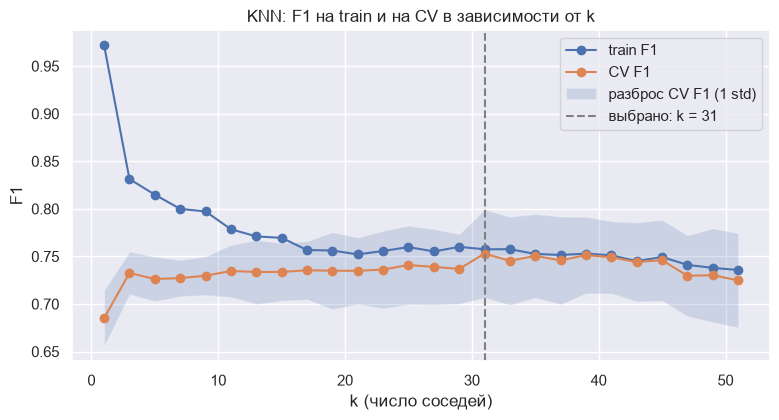

k,1,3,5,7,9,11,13,15,17,19,21,23,25,27,29,31,33,35,37,39,41,43,45,47,49,51
train F1,0.972,0.831,0.815,0.800,0.797,0.779,0.771,0.770,0.757,0.756,0.752,0.756,0.760,0.755,0.760,0.757,0.758,0.753,0.752,0.753,0.751,0.745,0.749,0.741,0.738,0.736
CV F1,0.685,0.733,0.726,0.727,0.730,0.735,0.734,0.734,0.735,0.735,0.735,0.736,0.741,0.739,0.737,0.753,0.745,0.751,0.746,0.751,0.749,0.744,0.746,0.730,0.730,0.725
CV F1 std,0.029,0.022,0.023,0.019,0.020,0.027,0.034,0.030,0.031,0.040,0.035,0.041,0.041,0.040,0.037,0.046,0.046,0.044,0.046,0.040,0.038,0.042,0.043,0.043,0.049,0.050


In [ ]:
knn_pipe = Pipeline([
    ("prep", make_preprocessor(scale=True)),  # KNN без масштабирования не работает (раздел 13.1)
    ("model", KNeighborsClassifier()),
])
k_grid = list(range(1, 52, 2))
knn_search = GridSearchCV(
    knn_pipe,
    param_grid={"model__n_neighbors": k_grid},
    scoring=SCORING["F1"],
    cv=cv,                    # те же 5 фолдов
    return_train_score=True,
)
knn_search.fit(X_train, y_train)  # при равных CV F1 выбирается первое (меньшее) k
best_k = knn_search.best_params_["model__n_neighbors"]

k_res = pd.DataFrame({
    "k": k_grid,
    "train F1": knn_search.cv_results_["mean_train_score"],
    "CV F1": knn_search.cv_results_["mean_test_score"],
    "CV F1 std": knn_search.cv_results_["std_test_score"],
}).set_index("k")

plt.figure(figsize=(9, 4.3))
plt.plot(k_res.index, k_res["train F1"], marker="o", label="train F1")
plt.plot(k_res.index, k_res["CV F1"], marker="o", label="CV F1")
plt.fill_between(k_res.index, k_res["CV F1"] - k_res["CV F1 std"], k_res["CV F1"] + k_res["CV F1 std"],
                 alpha=0.2, label="разброс CV F1 (1 std)")
plt.axvline(best_k, color="gray", linestyle="--", label=f"выбрано: k = {best_k}")
plt.xlabel("k (число соседей)")
plt.ylabel("F1")
plt.title("KNN: F1 на train и на CV в зависимости от k")
plt.legend()
plt.show()

with pd.option_context("display.max_columns", None):  # показать все 26 значений k
    display(k_res.round(3).T)

**Вывод:**
- При k = 1 на train почти идеально (0.97), а на CV плохо (0.69): каждый пассажир - сам себе ближайший сосед, модель просто помнит train.
- С ростом k train и CV сближаются, а после k = 45 качество падает - ответ слишком усредняется.
- Лучшее k = 31 (CV F1 0.753), но от k = 3 до 45 результат почти одинаковый (0.73-0.75), так что точное значение k не так важно.

### 13.3. Итоговая модель KNN

In [ ]:
knn = knn_search.best_estimator_  # Pipeline с лучшим k, GridSearchCV уже обучил его на всём train
display(run_cv("KNN", knn))

,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
KNN,0.7575,0.8189,0.7894,0.7214,0.753,0.8554,0.0463


**Вывод:** KNN с k = 31 на уровне SVM и леса (CV F1 0.753). На train и на CV качество одинаковое - с 31 соседом запомнить отдельных пассажиров нельзя. Но от фолда к фолду результат скачет сильнее, чем у леса (0.046 против 0.024).

## 14. Честное сравнение моделей
Все модели учились на одном train, проверялись на одних и тех же фолдах и будут оценены на одном test. Лучшую выбираем по CV, test открываем один раз.

### 14.1. Выбор лучшей модели по CV
Есть тонкость. Глубину дерева и k у KNN мы выбрали как лучшие из многих вариантов на тех же фолдах, поэтому их CV F1 немного "везучие" - завышены. У леса, бустинга и SVM параметры заданы заранее, вариант был один.

Чтобы условия были равными, для дерева и KNN считаем **вложенную кросс-валидацию**: на каждом фолде глубина (или k) выбирается заново, только по обучающей части, а проверяется на той части, которая в выборе не участвовала.

In [ ]:
# вложенная CV: GridSearchCV целиком (вместе с подбором параметра) проходит через те же 5 внешних фолдов
nested_f1 = {}
for name, search in [("Decision Tree", tree_search), ("KNN", knn_search)]:
    res = cross_validate(search, X_train, y_train, cv=cv, scoring=SCORING["F1"], return_estimator=True)
    nested_f1[name] = res["test_score"]
    chosen = [list(est.best_params_.values())[0] for est in res["estimator"]]
    print(f"{name}: обычная CV F1 = {cv_results[name]['CV F1']:.4f}, вложенная CV F1 = {res['test_score'].mean():.4f}, "
          f"параметр, выбранный в каждом фолде: {chosen}")

Decision Tree: обычная CV F1 = 0.7632, вложенная CV F1 = 0.7402, параметр, выбранный в каждом фолде: [3, 5, 7, 3, 3]


KNN: обычная CV F1 = 0.7530, вложенная CV F1 = 0.7254, параметр, выбранный в каждом фолде: [27, 23, 7, 23, 11]


**Вывод:** честная оценка дерева - 0.740 вместо 0.763, KNN - 0.725 вместо 0.753. К тому же в разных фолдах выбиралась разная глубина (3, 5, 7) и разное k (от 7 до 27) - точные значения во многом случайны.

In [ ]:
MODEL_NAMES = ["Baseline (most_frequent)", "Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]

cv_table = pd.DataFrame(cv_results).T.loc[MODEL_NAMES]
honest = cv_table["CV F1"].copy()
for name, scores in nested_f1.items():
    honest[name] = scores.mean()  # для дерева и KNN - оценка вложенной CV
cv_table.insert(0, "честная CV F1", honest)
cv_table = cv_table.sort_values("честная CV F1", ascending=False)
cv_table.index.name = "Модель"
best_name = cv_table.index[0]
display(cv_table.round(4))
print(f"Лучшая модель по честной CV-оценке F1: {best_name}")

# F1 по фолдам (для дерева и KNN - вложенная CV); фолды одинаковые, поэтому сравнение попарное
honest_folds = {name: nested_f1.get(name, cv_fold_f1[name]) for name in MODEL_NAMES}
fold_table = pd.DataFrame(honest_folds, index=[f"фолд {i + 1}" for i in range(N_FOLDS)]).T.loc[cv_table.index]
display(fold_table.round(4))
for name in cv_table.index[1:]:
    wins = (fold_table.loc[best_name] > fold_table.loc[name]).sum()
    print(f"{best_name} лучше, чем {name}: на {wins} фолдах из {N_FOLDS}")

,честная CV F1,train F1,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 std
Модель,,,,,,,,
Random Forest,0.7601,0.8778,0.8259,0.8109,0.7178,0.7601,0.8816,0.0244
SVM,0.7528,0.7868,0.8230,0.8089,0.7067,0.7528,0.8570,0.0311
Gradient Boosting,0.7441,0.8922,0.8146,0.7924,0.7032,0.7441,0.8904,0.0366
Decision Tree,0.7402,0.7756,0.8287,0.8097,0.7290,0.7632,0.8584,0.0571
KNN,0.7254,0.7575,0.8189,0.7894,0.7214,0.7530,0.8554,0.0463
Baseline (most_frequent),0.0000,0.0000,0.6166,0.0000,0.0000,0.0000,0.5000,0.0000


Лучшая модель по честной CV-оценке F1: Random Forest


,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5
Модель,,,,,
Random Forest,0.7810,0.7207,0.7800,0.7767,0.7423
SVM,0.7850,0.7379,0.7843,0.7547,0.7021
Gradient Boosting,0.7963,0.7170,0.7475,0.6923,0.7677
Decision Tree,0.7679,0.6939,0.7143,0.7407,0.7843
KNN,0.7636,0.7255,0.7292,0.6796,0.7292
Baseline (most_frequent),0.0000,0.0000,0.0000,0.0000,0.0000


Random Forest лучше, чем SVM: на 2 фолдах из 5
Random Forest лучше, чем Gradient Boosting: на 3 фолдах из 5
Random Forest лучше, чем Decision Tree: на 4 фолдах из 5
Random Forest лучше, чем KNN: на 4 фолдах из 5
Random Forest лучше, чем Baseline (most_frequent): на 5 фолдах из 5


**Вывод:**
- По честной оценке лучший - **Random Forest** (0.760), дальше SVM (0.753), бустинг (0.744), дерево (0.740) и KNN (0.725). Все выше 0.70.
- Лес опережает остальных немного, зато он самый стабильный. Его и считаем лучшей моделью: разбираем его ошибки (раздел 16) и сохраняем (раздел 17). Решение принято до того, как мы посмотрели на test.

### 14.2. Единственная оценка на test

In [ ]:
models = {
    "Baseline (most_frequent)": baseline,
    "Decision Tree": tree,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "SVM": svm,
    "KNN": knn,
}
# все модели уже обучены на всём train; test используется здесь первый и единственный раз
test_table = pd.DataFrame({name: metrics_on(model, X_test, y_test) for name, model in models.items()}).T
test_table["train F1"] = [f1_score(y_train, model.predict(X_train), zero_division=0) for model in models.values()]
test_table["разрыв train - test"] = test_table["train F1"] - test_table["F1"]
test_table["честная CV F1"] = cv_table["честная CV F1"]
test_table[f"F1 > {F1_THRESHOLD}"] = test_table["F1"] > F1_THRESHOLD
test_table = test_table.sort_values("F1", ascending=False)
test_table.index.name = "Модель"
test_table.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,train F1,разрыв train - test,честная CV F1,F1 > 0.7
Модель,,,,,,,,,
SVM,0.8380,0.8125,0.7536,0.7820,0.8535,0.7831,0.0012,0.7528,True
Decision Tree,0.8324,0.8000,0.7536,0.7761,0.8639,0.7849,0.0088,0.7402,True
Random Forest,0.8380,0.8448,0.7101,0.7717,0.8491,0.8798,0.1082,0.7601,True
Gradient Boosting,0.8212,0.8246,0.6812,0.7460,0.8544,0.8795,0.1335,0.7441,True
KNN,0.8156,0.8000,0.6957,0.7442,0.8518,0.7604,0.0162,0.7254,True
Baseline (most_frequent),0.6145,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,False


**Вывод:**
- Все пять моделей прошли порог F1 > 0.70: от 0.744 (KNN) до 0.782 (SVM).
- Лес, выбранный по CV, на test третий (0.772). От SVM он отстаёт на одного угаданного пассажира - это случайность. Менять выбор по test нельзя, это была бы подгонка.
- Дерево не переобучилось: на train 0.785, на test 0.776.
- На test результаты чуть выше, чем на CV, но в пределах обычного разброса - подозрений на утечку нет.

### 14.3. Матрицы ошибок на test

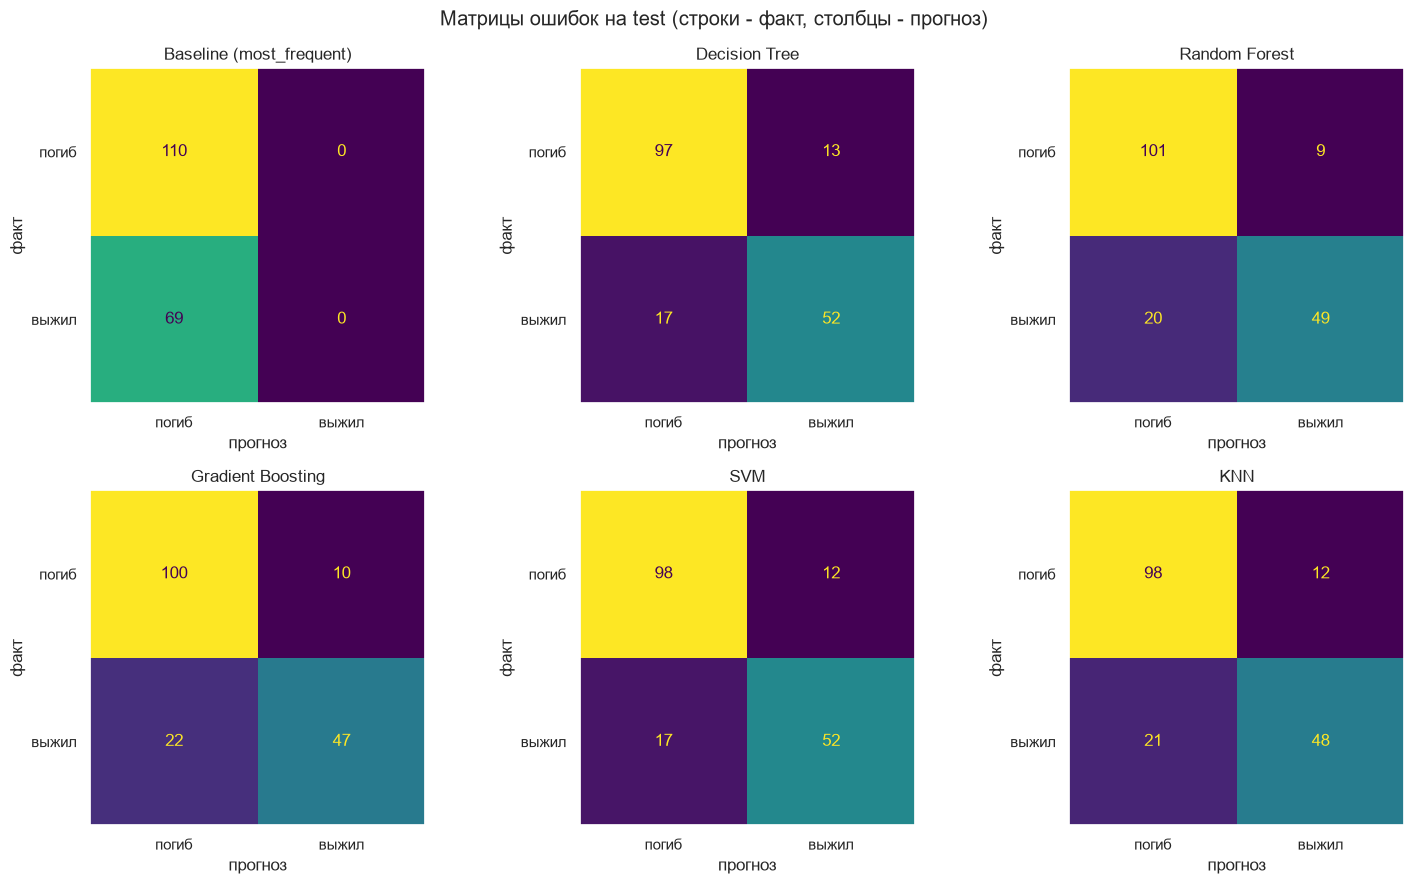

,TN,FP,FN,TP,ошибок всего
Baseline (most_frequent),110,0,69,0,69
Decision Tree,97,13,17,52,30
Random Forest,101,9,20,49,29
Gradient Boosting,100,10,22,47,32
SVM,98,12,17,52,29
KNN,98,12,21,48,33


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["погиб", "выжил"],
                                          colorbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("прогноз")
    ax.set_ylabel("факт")
    ax.grid(False)
plt.suptitle("Матрицы ошибок на test (строки - факт, столбцы - прогноз)")
plt.tight_layout()
plt.show()

cm_rows = {}
for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    cm_rows[name] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "ошибок всего": fp + fn}
pd.DataFrame(cm_rows).T

**Вывод:**
- Все модели ошибаются примерно одинаково часто: 29-33 ошибки из 179 (у baseline - 69).
- У всех моделей пропусков (FN) больше, чем ложных срабатываний (FP): модели чаще считают погибшим того, кто выжил. У леса это в основном взрослые мужчины, выжившие вопреки общей картине (раздел 16).
- Лес самый "осторожный": реже всех ошибочно говорит "выжил" (9 раз), но пропускает больше выживших (20).

### 14.4. F1 на CV и на test

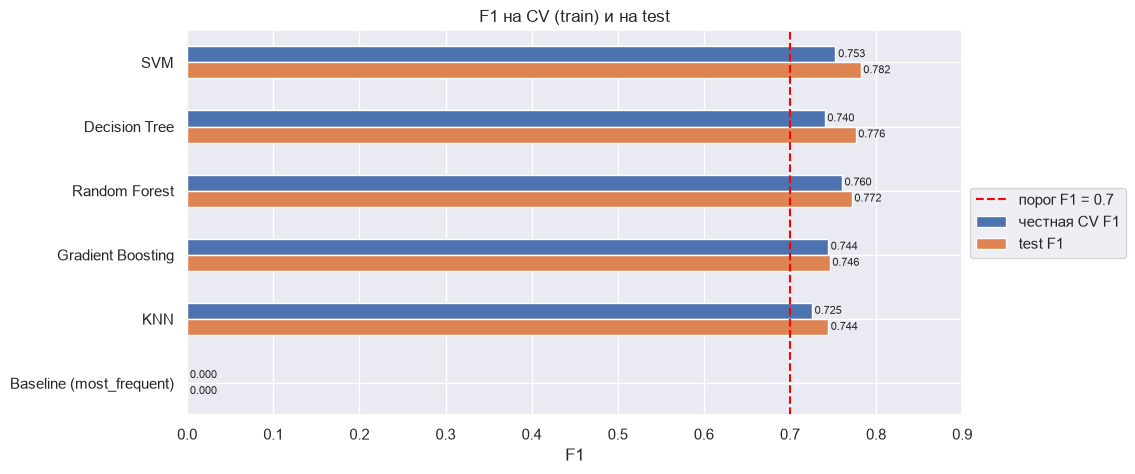

In [ ]:
f1_compare = pd.DataFrame({
    "честная CV F1": cv_table["честная CV F1"],
    "test F1": test_table["F1"],
}).loc[test_table.index]

ax = f1_compare.plot.barh(figsize=(10, 5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.axvline(F1_THRESHOLD, color="red", linestyle="--", label=f"порог F1 = {F1_THRESHOLD}")
ax.invert_yaxis()  # лучшая по test - сверху
ax.set_xlim(0, 0.9)
ax.set_xlabel("F1")
ax.set_ylabel("")
ax.set_title("F1 на CV (train) и на test")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

### Итог раздела 14
- Лучшая модель по честной CV - **Random Forest**. На test все пять моделей прошли порог (0.744-0.782).
- Модели различаются мало, потому что опираются на одну и ту же информацию (пол, обращение, класс, цена билета) и ошибаются на одних и тех же "трудных" пассажирах.
- Различия всё же есть: лес и бустинг сильнее запоминают train, дерево простое, но нестабильное, SVM и KNN без масштабирования не работают, а KNN сильнее скачет от фолда к фолду.
- До F1 = 1 не дотянет никакая модель: у части пассажиров одинаковые данные и разная судьба (раздел 2.4).

## 15. Важность признаков

### 15.1. MDI: дерево, лес и бустинг
Встроенная важность из разделов 9-11 на одном графике.

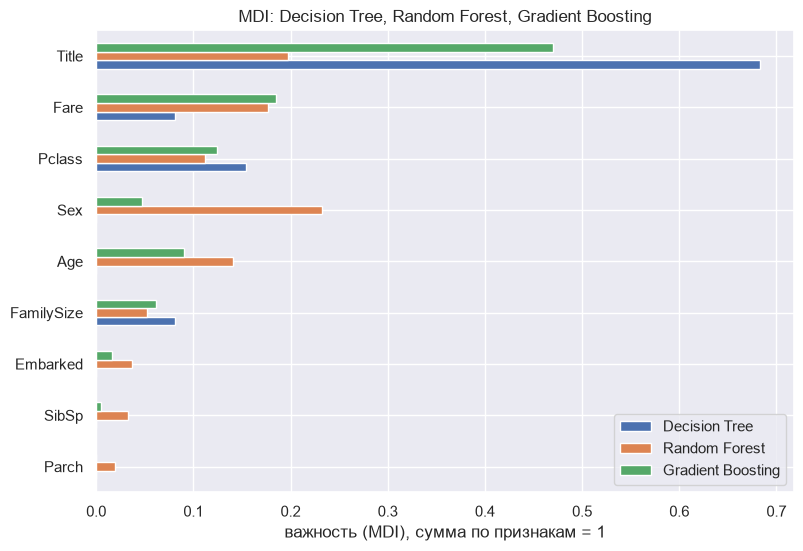

,Decision Tree,Random Forest,Gradient Boosting,место DT,место RF,место GB
Title,0.684,0.198,0.470,1,2,1
Fare,0.081,0.177,0.185,4,3,2
Pclass,0.154,0.112,0.124,2,5,3
Sex,0.000,0.232,0.047,5,1,6
Age,0.000,0.141,0.090,5,4,4
FamilySize,0.082,0.052,0.062,3,6,5
Embarked,0.000,0.036,0.016,5,7,7
SibSp,0.000,0.032,0.005,5,8,8
Parch,0.000,0.019,0.000,5,9,9


Пол и обращение вместе (Sex + Title): {'Decision Tree': 0.684, 'Random Forest': 0.43, 'Gradient Boosting': 0.518}


In [ ]:
mdi = pd.DataFrame({"Decision Tree": tree_imp, "Random Forest": rf_imp, "Gradient Boosting": gb_imp})

order = mdi.mean(axis=1).sort_values().index  # самый важный в среднем - сверху
mdi.loc[order].plot.barh(figsize=(9, 6))
plt.xlabel("важность (MDI), сумма по признакам = 1")
plt.title("MDI: Decision Tree, Random Forest, Gradient Boosting")
plt.show()

mdi_table = mdi.copy()
for name, short in [("Decision Tree", "DT"), ("Random Forest", "RF"), ("Gradient Boosting", "GB")]:
    mdi_table[f"место {short}"] = mdi[name].rank(ascending=False, method="min").astype(int)
display(mdi_table.loc[order[::-1]].round(3))
print("Пол и обращение вместе (Sex + Title):", (mdi.loc["Sex"] + mdi.loc["Title"]).round(3).to_dict())

**Вывод:**
- Если сложить пол и обращение, это главный признак у всех трёх моделей (0.68, 0.43 и 0.52). Дальше - цена билета и класс, потом возраст и семья. Порт и родственники - в конце.
- Самое заметное расхождение - пол: у дерева 0, у леса 1-е место. Пол и `Title_Mr` несут почти одно и то же, и важность достаётся тому, о чём модель спросила первым.

### 15.2. Permutation importance на test
У MDI есть минусы: она считается на train, завышает признаки с большим числом значений, а у SVM и KNN её нет вовсе. Поэтому проверяем другим способом: перемешиваем в test значения одного признака и смотрим, насколько упал F1. Чем сильнее упал, тем больше модель на этот признак опирается.

Это анализ уже выбранных моделей: по этим цифрам ничего не меняем, поэтому это не подгонка под test.

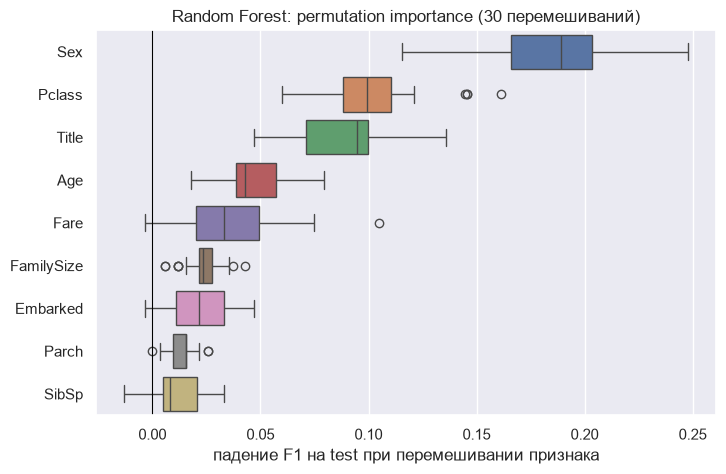

,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Sex,0.0000,0.1863,0.0369,0.2176,0.1694
Pclass,0.0344,0.1007,0.1085,0.0230,0.0308
Title,0.3694,0.0890,0.2804,0.0685,0.1448
Age,0.0000,0.0457,0.0308,0.0261,0.0250
Fare,0.0148,0.0367,0.0440,0.0289,0.0139
FamilySize,0.0478,0.0237,0.0299,0.0056,0.0089
Embarked,0.0000,0.0214,0.0175,0.0122,0.0317
Parch,0.0000,0.0141,0.0000,-0.0001,0.0159
SibSp,0.0000,0.0107,-0.0066,0.0251,0.0317


In [ ]:
FINAL_MODELS = ["Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]
perm_raw = {
    name: permutation_importance(models[name], X_test, y_test, scoring=SCORING["F1"],
                                 n_repeats=30, random_state=RANDOM_STATE)
    for name in FINAL_MODELS
}
perm = pd.DataFrame({name: r.importances_mean for name, r in perm_raw.items()}, index=X_test.columns)

# лучшая модель: падение F1 в каждом из 30 перемешиваний
order = perm[best_name].sort_values(ascending=False).index
repeats = pd.DataFrame(perm_raw[best_name].importances.T, columns=X_test.columns)[order]
plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=repeats, orient="h")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("падение F1 на test при перемешивании признака")
ax.set_title(f"{best_name}: permutation importance (30 перемешиваний)")
plt.show()

perm.loc[order].round(4)  # среднее падение F1 для всех пяти моделей

**Вывод:**
- Для леса важнее всего пол (F1 падает на 0.19), потом класс (0.10) и обращение (0.09).
- Цена билета по MDI была у леса на 3-м месте, а здесь только на 5-м: MDI её завысила. Класс, наоборот, поднялся с 5-го места на 2-е.
- У других моделей картина похожая: для SVM и KNN главный признак - пол, для дерева и бустинга - обращение. KNN реагирует даже на слабые признаки (порт, родственники): в расстоянии участвуют все столбцы.

### 15.3. Перемешивание похожих признаков вместе
Если перемешать только пол, модель всё равно узнает его по обращению (`Mr`, `Mrs`), и важность пола покажется меньше, чем на самом деле. Поэтому перемешаем похожие признаки вместе, одной и той же перестановкой.

In [ ]:
GROUPS = {
    "Sex + Title": ["Sex", "Title"],
    "семья: SibSp + Parch + FamilySize": ["SibSp", "Parch", "FamilySize"],
    "Pclass + Fare": ["Pclass", "Fare"],
}


def group_permutation(model, cols, n_repeats=30):
    # среднее падение F1 на test, если перемешать группу столбцов одной и той же перестановкой строк
    rng = np.random.default_rng(RANDOM_STATE)
    base = f1_score(y_test, model.predict(X_test))
    drops = []
    for _ in range(n_repeats):
        idx = rng.permutation(len(X_test))
        X_perm = X_test.copy()
        for col in cols:
            X_perm[col] = X_test[col].to_numpy()[idx]  # у всех столбцов группы одна и та же перестановка
        drops.append(base - f1_score(y_test, model.predict(X_perm), zero_division=0))
    return np.mean(drops)


group_table = pd.DataFrame({
    name: {group: group_permutation(models[name], cols) for group, cols in GROUPS.items()}
    for name in FINAL_MODELS
})
# для сравнения: сумма падений, если перемешивать признаки группы по отдельности
single_sum = pd.DataFrame({
    name: {group: perm.loc[cols, name].sum() for group, cols in GROUPS.items()}
    for name in FINAL_MODELS
})
display(group_table.round(4))
print("Сумма отдельных перемешиваний тех же признаков:")
single_sum.round(4)

,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Sex + Title,0.3695,0.3323,0.3236,0.3624,0.3185
семья: SibSp + Parch + FamilySize,0.0503,0.0381,0.0191,0.0617,0.0654
Pclass + Fare,0.0543,0.1375,0.1594,0.0692,0.0904


Сумма отдельных перемешиваний тех же признаков:


,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Sex + Title,0.3694,0.2753,0.3174,0.2861,0.3143
семья: SibSp + Parch + FamilySize,0.0478,0.0485,0.0233,0.0307,0.0565
Pclass + Fare,0.0492,0.1374,0.1525,0.0519,0.0448


**Вывод:**
- Пол и обращение вместе - самая важная информация: без них F1 любой модели падает примерно с 0.74-0.78 до 0.41-0.44.
- У леса и SVM вместе они дают больше, чем по отдельности (лес: 0.33 против 0.28). Значит, при перемешивании по одному модель брала пол из обращения - по отдельности важность похожих признаков занижается.
- Класс с ценой билета и семья дают меньше, но тоже не ноль.

### 15.4. Сравнение с анализом данных
Места признаков (1 - самый важный) по всем способам и вывод из раздела 5.

In [ ]:
eda_view = pd.Series({
    "Sex": "главный (5.1)",
    "Title": "главный, отделяет мальчиков (5.2)",
    "Pclass": "сильный (5.1)",
    "Fare": "сильный, связан с классом (5.4)",
    "Age": "средний, в основном дети (5.3)",
    "FamilySize": "средний, форма горки (5.6)",
    "SibSp": "слабый сам по себе, часть семьи (5.8)",
    "Parch": "слабый сам по себе, часть семьи (5.8)",
    "Embarked": "слабый, через класс (5.5)",
})

short = {"Decision Tree": "DT", "Random Forest": "RF", "Gradient Boosting": "GB", "SVM": "SVM", "KNN": "KNN"}
ranks = pd.concat(
    {**{f"MDI {short[n]}": mdi[n] for n in mdi.columns},
     **{f"перест. {short[n]}": perm[n] for n in FINAL_MODELS}},
    axis=1,
).rank(ascending=False, method="min").astype(int)
ranks["средний ранг"] = ranks.mean(axis=1).round(1)
ranks = ranks.sort_values("средний ранг")
ranks.insert(0, "EDA (раздел 5)", eda_view)
ranks

,EDA (раздел 5),MDI DT,MDI RF,MDI GB,перест. DT,перест. RF,перест. GB,перест. SVM,перест. KNN,средний ранг
Title,"главный, отделяет мальчиков (5.2)",1,2,1,1,3,1,2,2,1.6
Sex,главный (5.1),5,1,6,5,1,4,1,1,3.0
Pclass,сильный (5.1),2,5,3,3,2,2,6,5,3.5
Fare,"сильный, связан с классом (5.4)",4,3,2,4,5,3,3,8,4.0
Age,"средний, в основном дети (5.3)",5,4,4,5,4,5,4,6,4.6
FamilySize,"средний, форма горки (5.6)",3,6,5,2,6,6,8,9,5.6
Embarked,"слабый, через класс (5.5)",5,7,7,5,7,7,7,3,6.0
SibSp,"слабый сам по себе, часть семьи (5.8)",5,8,8,5,9,9,5,4,6.6
Parch,"слабый сам по себе, часть семьи (5.8)",5,9,9,5,8,8,9,7,7.5


**Вывод:**
- **Самые важные признаки:** пол и обращение, затем класс и цена билета, затем возраст и размер семьи. Наименее важны порт, `SibSp` и `Parch`.
- Это почти точно совпадает с тем, что мы ожидали по анализу данных (раздел 5), включая слабый порт.
- Места одного признака меняются от способа к способу (у пола - от 1-го до 6-го). Это особенность способов подсчёта, а не данных.

### 15.5. Можно ли считать важный признак причиной выживания?
**Нет.** Важность показывает, на что опирается модель, то есть связь в данных, а не причину.
- **Данные - наблюдения, а не эксперимент.** Никто не пересаживал пассажиров из класса в класс, чтобы посмотреть, что изменится.
- **Бывают скрытые причины.** Пример из наших данных - порт: в Шербуре выживали чаще, потому что там садились пассажиры 1-го класса (раздел 5.5). Сам порт спасти не мог.
- **Важность зависит от модели.** У дерева важность пола 0, у леса - 1-е место. Настоящая причина от модели не зависела бы.
- **Настоящая причина - правила эвакуации** ("женщины и дети первыми"). Пол с ними связан, но сам по себе никого не спасал.

Модель отвечает на вопрос "кто выжил", а не "почему".

## 16. Анализ ошибок лучшей модели (Random Forest)
Разбираем ошибки леса на test. Модель после этого не меняется - это только анализ.

### 16.1. Подробная матрица ошибок

In [ ]:
best_model = models[best_name]
pred = pd.Series(best_model.predict(X_test), index=X_test.index)
proba = pd.Series(best_model.predict_proba(X_test)[:, 1], index=X_test.index)  # доля деревьев леса, сказавших "выжил"
outcome = pd.Series(np.select([pred == y_test, pred == 1], ["верно", "FP"], default="FN"),
                    index=X_test.index, name="ответ")  # тип ответа для каждого пассажира

labels = ["погиб", "выжил"]
cm_abs = pd.DataFrame(confusion_matrix(y_test, pred),
                      index=[f"факт: {s}" for s in labels], columns=[f"прогноз: {s}" for s in labels])
print("В штуках:")
display(cm_abs)
print("Доли по строкам, % (какая часть каждого факта получила такой прогноз):")
display((cm_abs.div(cm_abs.sum(axis=1), axis=0) * 100).round(1))
print("Доли по столбцам, % (какая часть каждого прогноза верна):")
display((cm_abs.div(cm_abs.sum(axis=0), axis=1) * 100).round(1))

В штуках:


,прогноз: погиб,прогноз: выжил
факт: погиб,101,9
факт: выжил,20,49


Доли по строкам, % (какая часть каждого факта получила такой прогноз):


,прогноз: погиб,прогноз: выжил
факт: погиб,91.8,8.2
факт: выжил,29.0,71.0


Доли по столбцам, % (какая часть каждого прогноза верна):


,прогноз: погиб,прогноз: выжил
факт: погиб,83.5,15.5
факт: выжил,16.5,84.5


**Вывод:**
- Лес нашёл 71% выживших, а 20 выживших (29%) посчитал погибшими. Погибших он почти всех определил верно, ошибочно "спас" только 9 (8%).
- Если лес говорит "выжил", это верно в 85% случаев.
- Главная слабость - пропуски выживших: их вдвое больше, чем ложных срабатываний.

### 16.2. В каких группах модель ошибается чаще
В среднем по test ошибочны 29 ответов из 179 (16%).

In [ ]:
test_df = X_test.assign(
    Survived=y_test,
    pred=pred,
    FP=(pred == 1) & (y_test == 0),
    FN=(pred == 0) & (y_test == 1),
)
test_df["возраст"] = "взрослый"
test_df.loc[test_df["Age"] <= 12, "возраст"] = "ребёнок (до 12)"
test_df.loc[test_df["Age"].isna(), "возраст"] = "нет данных"
test_df["семья"] = pd.cut(test_df["FamilySize"], bins=[0, 1, 4, 11], labels=["один", "2-4", "5 и больше"])


def error_table(by):
    # ошибки модели на test по группам пассажиров
    g = test_df.groupby(by, observed=True)
    table = pd.DataFrame({
        "пассажиров": g.size(),
        "выжило, %": g["Survived"].mean() * 100,
        "предсказано 'выжил', %": g["pred"].mean() * 100,
        "FP": g["FP"].sum(),
        "FN": g["FN"].sum(),
    })
    table["ошибок, %"] = (table["FP"] + table["FN"]) / table["пассажиров"] * 100
    return table.round(1)


for by in [["Pclass", "Sex"], "Title", "возраст", "семья"]:
    display(error_table(by))

пассажиров  выжило, %  предсказано 'выжил', %  FP  FN  \
Pclass Sex                                                             
1      female          15       93.3                   100.0   1   0   
       male            30       36.7                    20.0   2   7   
2      female          18       94.4                   100.0   1   0   
       male            16       18.8                     6.2   0   2   
3      female          28       50.0                    46.4   4   5   
       male            72       13.9                     6.9   1   6   

               ошибок, %  
Pclass Sex                
1      female        6.7  
       male         30.0  
2      female        5.6  
       male         12.5  
3      female       32.1  
       male          9.7

,пассажиров,"выжило, %","предсказано 'выжил', %",FP,FN,"ошибок, %"
Title,,,,,,
Master,9,66.7,66.7,0,0,0.0
Miss,41,68.3,75.6,5,2,17.1
Mr,105,17.1,3.8,1,15,15.2
Mrs,19,84.2,73.7,1,3,21.1
Rare,5,20.0,60.0,2,0,40.0


,пассажиров,"выжило, %","предсказано 'выжил', %",FP,FN,"ошибок, %"
возраст,,,,,,
взрослый,125,40.0,30.4,4,16,16.0
нет данных,40,30.0,30.0,4,4,20.0
ребёнок (до 12),14,50.0,57.1,1,0,7.1


,пассажиров,"выжило, %","предсказано 'выжил', %",FP,FN,"ошибок, %"
семья,,,,,,
один,103,32.0,25.2,4,11,14.6
2-4,64,53.1,46.9,5,9,21.9
5 и больше,12,16.7,16.7,0,0,0.0


**Вывод:**
- Больше всего ошибок там, где мы и ожидали по анализу данных: у мужчин 1-го класса (30%) и женщин 3-го класса (32%). Это треть пассажиров test, но почти две трети ошибок (18 из 29).
- Мужчин 1-го класса лес чаще ошибочно считает погибшими: выжили 37%, а он "спас" только 20%. У женщин 3-го класса он ошибается в обе стороны - там выжила ровно половина.
- 15 из 20 пропусков - взрослые мужчины (`Mr`): выживших мужчин по нашим данным почти не отличить от погибших.
- Почти без ошибок - женщины 1-2 класса, мальчики и дети. Группы в test маленькие, поэтому смотрим только на крупные различия.

### 16.3. Разбор конкретных ошибок
Чтобы не выбирать удобные примеры, правило задали заранее: 3 выживших, в чьей гибели лес был больше всего уверен (FN), и 3 погибших, в чьём спасении он был больше всего уверен (FP). Для каждого показано, сколько выжило в его группе (класс и пол) на train.

In [ ]:
fn_idx = proba[outcome == "FN"].sort_values().index[:3]
fp_idx = proba[outcome == "FP"].sort_values(ascending=False).index[:3]
case_idx = list(fn_idx) + list(fp_idx)

group_rate = train_df.groupby(["Pclass", "Sex"])[TARGET].mean() * 100  # доля выживших на train по классу и полу
cases = df.loc[case_idx, ["Name", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].assign(
    Title=X_test.loc[case_idx, "Title"],
    ошибка=outcome[case_idx],
    вероятность_выжить=proba[case_idx].round(2),
    выжил_на_самом_деле=y_test[case_idx],
    выжило_в_группе_на_train=[round(group_rate[(df.loc[i, "Pclass"], df.loc[i, "Sex"])], 1) for i in case_idx],
)
cases

,Name,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,ошибка,вероятность_выжить,выжил_на_самом_деле,выжило_в_группе_на_train
444,"Johannesen-Bratthammer, Mr. Bernt",3,male,NaN,0,0,8.1125,S,Mr,FN,0.02,1,13.5
17,"Williams, Mr. Charles Eugene",2,male,NaN,0,0,13.0000,S,Mr,FN,0.03,1,15.2
570,"Harris, Mr. George",2,male,62.0,0,0,10.5000,S,Mr,FN,0.06,1,15.2
199,"Yrois, Miss. Henriette (""Mrs Harbeck"")",2,female,24.0,0,0,13.0000,S,Miss,FP,0.95,0,91.4
297,"Allison, Miss. Helen Loraine",1,female,2.0,1,2,151.5500,S,Miss,FP,0.88,0,97.5
501,"Canavan, Miss. Mary",3,female,21.0,0,0,7.7500,Q,Miss,FP,0.85,0,50.0


**Разбор:**
- **Пропуски (FN)** - трое одиноких мужчин из 2-3 класса. В их группах выжили только 14-15%, по данным это типичные погибшие, и лес дал им 2-6% шансов. Почему они спаслись, в данных нет: где были в момент столкновения, успели ли к шлюпке, просто повезло.
- **Ложные срабатывания (FP)** - женщина 24 лет из 2-го класса и девочка 2 лет из 1-го класса (в их группах выжили 91% и 98%). Лес уверен в их спасении, но обе погибли - по данным это не объяснить.
- Третья - молодая одинокая женщина 3-го класса из трудной группы (выжила половина): обращение `Miss`, возраст и порт Q склонили модель к ответу "выжил".
- **Итог:** у этих людей данные типичны для противоположной судьбы. Это не недостаток модели, а предел того, что можно узнать из этих 9 признаков.

### 16.4. Не держится ли качество на идентификаторах или подозрительных признаках
С самого начала мы убрали `PassengerId`, `Name`, `Ticket` (идентификаторы) и `Cabin` (пропуски и подозрение на информацию "после события"). `Title` идентификатором не является: в самой маленькой группе 23 человека.

Теперь проверим по CV на train, что было бы, если бы мы их использовали:
- дерево только на `PassengerId`;
- лес с нашими признаками и `PassengerId`;
- лес с нашими признаками и флагом "каюта известна".

In [ ]:
X_train_extra = X_train.assign(
    PassengerId=df.loc[X_train.index, "PassengerId"],
    HasCabin=df.loc[X_train.index, "Cabin"].notna().astype(int),  # 1 - номер каюты известен
)

# дерево только на PassengerId
id_res = cross_validate(DecisionTreeClassifier(random_state=RANDOM_STATE), X_train_extra[["PassengerId"]], y_train,
                        cv=cv, scoring=SCORING["F1"], return_train_score=True)
print(f"Дерево только на PassengerId: train F1 = {id_res['train_score'].mean():.3f}, "
      f"CV F1 = {id_res['test_score'].mean():.3f}")


def rf_with(extra_num):
    # CV F1 леса (параметры из 7.3) на наших признаках плюс дополнительные числовые столбцы
    pipe = Pipeline([("prep", make_preprocessor(False, NUM_COLS + extra_num, CAT_COLS)), ("model", rf_model)])
    return cross_validate(pipe, X_train_extra, y_train, cv=cv, scoring=SCORING["F1"])["test_score"]


extra_check = {
    "наши признаки (B)": cv_fold_f1["Random Forest"],
    "B + PassengerId": rf_with(["PassengerId"]),
    "B + HasCabin": rf_with(["HasCabin"]),
}
base_folds = extra_check["наши признаки (B)"]
pd.DataFrame({
    "CV F1": {k: v.mean() for k, v in extra_check.items()},
    "CV F1 std": {k: v.std() for k, v in extra_check.items()},
    "отличие от B": {k: v.mean() - base_folds.mean() for k, v in extra_check.items()},
    "лучше B на фолдах": {k: int((v > base_folds).sum()) for k, v in extra_check.items()},
}).round(4)

Дерево только на PassengerId: train F1 = 1.000, CV F1 = 0.378


,CV F1,CV F1 std,отличие от B,лучше B на фолдах
наши признаки (B),0.7601,0.0244,0.0000,0
B + PassengerId,0.7432,0.0354,-0.0169,1
B + HasCabin,0.7613,0.0276,0.0012,3


**Вывод:**
- Дерево на одном `PassengerId` идеально запоминает train (F1 1.0), но на CV даёт всего 0.378: номер пассажира ничего не говорит о новых людях. Так и выглядит признак-идентификатор.
- Если добавить `PassengerId` к лесу, качество падает (0.743 вместо 0.760) - номер только мешает.
- Флаг "каюта известна" ничего не добавляет (0.761 против 0.760), так что, отказавшись от него, мы ничего не потеряли.
- Качество модели держится на общих закономерностях (пол, обращение, класс, цена), а не на узнавании конкретных людей.

### Итог анализа ошибок
- Лес чаще пропускает выживших (20), чем ошибочно "спасает" погибших (9). Почти все пропуски - взрослые мужчины.
- Больше всего ошибок у мужчин 1-го класса и женщин 3-го класса - там судьба решалась почти как подброшенной монеткой.
- Многие ошибки с этими данными не исправить: у таких людей признаки типичны для противоположной судьбы.
- Идентификаторов и подозрительных признаков модель не использует.

## 17. Сохранение модели и прогноз для новых данных
- В `model.joblib` сохраняем лучшую модель целиком - вместе с предобработкой, потому что новые данные приходят "сырыми".
- Сохраняем модель, обученную только на train, - ту, чьи результаты в разделе 14: так её оценка на test честная. Для соревнования Kaggle (раздел 19) модель обучается на всех 891 пассажирах - там свой, отдельный тест.
- Открывать файл нужно той же версией scikit-learn (у нас 1.9.1).

In [ ]:
joblib.dump(best_model, MODEL_PATH)  # Pipeline: предобработка + Random Forest, обучен только на train
print(f"Сохранено: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} МБ), модель: {best_name}")

RAW_COLUMNS = ["Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]  # нужны для make_features


def predict_survival(data, model=None, return_proba=False):
    # Прогноз выживания для таблицы в формате Kaggle (столбцы как в Titanic-Dataset.csv).
    # Столбец Survived, если он есть, не используется. Без model загружается model.joblib.
    missing = [col for col in RAW_COLUMNS if col not in data.columns]
    if missing:
        raise ValueError(f"В данных нет столбцов: {missing}")
    if model is None:
        model = joblib.load(MODEL_PATH)
    features = make_features(data)  # те же 9 признаков, что при обучении (раздел 3)
    pred = pd.Series(model.predict(features), index=data.index, name="прогноз")
    if return_proba:
        proba = pd.Series(model.predict_proba(features)[:, 1], index=data.index, name="вероятность")
        return pred, proba
    return pred

Сохранено: model.joblib (4.3 МБ), модель: Random Forest


In [ ]:
# Проверка: загружаем модель из файла и предсказываем для строк test, заново прочитанных из исходного CSV
loaded_model = joblib.load(MODEL_PATH)
new_data = pd.read_csv(DATA_PATH).loc[X_test.index]  # сырые строки в формате Kaggle, вместе со столбцом Survived

new_pred, new_proba = predict_survival(new_data, model=loaded_model, return_proba=True)
display(new_data[["Name", "Pclass", "Sex", "Age", TARGET]].head(5).assign(
    прогноз=new_pred.head(5), вероятность=new_proba.head(5).round(2)))

assert (new_pred == pred).all(), "модель из файла должна давать те же прогнозы, что в разделе 14"
print(f"F1 на этих строках: {f1_score(new_data[TARGET], new_pred):.4f}")
print("Прогнозы модели из файла совпадают с прогнозами в разделах 14 и 16.")

,Name,Pclass,Sex,Age,Survived,прогноз,вероятность
565,"Davies, Mr. Alfred J",3,male,24.0,0,0,0.14
160,"Cribb, Mr. John Hatfield",3,male,44.0,0,0,0.11
553,"Leeni, Mr. Fahim (""Philip Zenni"")",3,male,22.0,1,0,0.13
860,"Hansen, Mr. Claus Peter",3,male,41.0,0,0,0.05
241,"Murphy, Miss. Katherine ""Kate""",3,female,NaN,1,1,0.76


F1 на этих строках: 0.7717
Прогнозы модели из файла совпадают с прогнозами в разделах 14 и 16.


**Проверка:** модель из файла даёт те же прогнозы и тот же F1 (0.7717), что в разделе 14. Чтобы применить её к новым пассажирам, достаточно `joblib.load` и `predict_survival` - обучать заново ничего не нужно.

## 18. Итоги
- **Данные:** 891 пассажир. Убрали идентификаторы (`PassengerId`, `Name`, `Ticket`) и `Cabin` (77% пропусков), добавили `Title` и `FamilySize` - всего 9 признаков. Разбиение 712/179 - как в презентации к лабораторной.
- **Как работали:** все решения - по кросс-валидации на train, test - один раз в конце. Пропуски и категории обрабатывались только по train.

In [ ]:
# итоговая таблица: метрики на test и честная CV-оценка F1
test_table[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "честная CV F1", f"F1 > {F1_THRESHOLD}"]].round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,честная CV F1,F1 > 0.7
Модель,,,,,,,
SVM,0.838,0.812,0.754,0.782,0.853,0.753,True
Decision Tree,0.832,0.800,0.754,0.776,0.864,0.740,True
Random Forest,0.838,0.845,0.710,0.772,0.849,0.760,True
Gradient Boosting,0.821,0.825,0.681,0.746,0.854,0.744,True
KNN,0.816,0.800,0.696,0.744,0.852,0.725,True
Baseline (most_frequent),0.615,0.000,0.000,0.000,0.500,0.000,False


- **Все пять моделей прошли порог F1 > 0.70:** SVM - 0.782, дерево - 0.776, лес - 0.772, бустинг - 0.746, KNN - 0.744 (baseline - 0).
- **Лучшая модель - Random Forest:** лучшая по честной CV (0.760) и самая стабильная. На test она третья, но отстаёт от первой всего на одного пассажира.
- **Главные признаки** у всех моделей и в анализе данных: пол и обращение, затем класс и цена билета. Это связь, а не причина.
- **Ошибки:** модель чаще пропускает выживших, чем "спасает" погибших; больше всего ошибок у мужчин 1-го класса и женщин 3-го. Идентификаторы на качество не влияют.
- **Kaggle:** в данных соревнования нет имён, поэтому модель для него строится без `Title`. Лучшей по CV снова оказался Random Forest (F1 0.758), прогноз для 1000 объектов сохранён в `submission.csv` (раздел 19).
- **Ограничения:** test маленький (один пассажир - это примерно 0.01 F1), порог 0.5 и параметры моделей не подбирались - это можно улучшить в лабораторной №3. Но безошибочной модели не будет: у части пассажиров одинаковые данные и разная судьба.

## 19. Соревнование Kaggle
Итоговый рейтинг группы считается в соревновании на Kaggle: обучаемся на `train.csv` соревнования, предсказываем 1000 объектов из `test.csv` и отправляем файл по шаблону `sample_submission.csv`. Метрика та же - F1 для класса 1.

Главное отличие от основной части: в данных соревнования нет имён, поэтому `Title` посчитать нельзя. Модель для Kaggle строим на 7 исходных признаках и `FamilySize`. Модель и порог выбираем по кросс-валидации на `train.csv`, а `test.csv` до отправки нужен только для прогноза. `Id` - технический номер, как признак его не используем.

### 19.1. Данные соревнования

In [ ]:
KAGGLE_DIR = DATA_DIR / "kaggle"
k_train = pd.read_csv(KAGGLE_DIR / "train.csv")
k_test = pd.read_csv(KAGGLE_DIR / "test.csv")
k_sample = pd.read_csv(KAGGLE_DIR / "sample_submission.csv")
print(f"train.csv: {k_train.shape}, test.csv: {k_test.shape}, sample_submission.csv: {k_sample.shape}")

# те же ли это 891 пассажир, что в основной части (порядок строк другой, поэтому сравниваем отсортированные таблицы)
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", TARGET]
same_rows = (k_train[cols].sort_values(cols).reset_index(drop=True)
             .equals(df[cols].sort_values(cols).reset_index(drop=True)))
print("train.csv - те же 891 пассажир, что в Titanic-Dataset.csv:", same_rows)
assert (k_test["Id"].values == k_sample["Id"].values).all()  # Id в test и в шаблоне идут в одном порядке
n_copies = k_test[cols[:-1]].merge(k_train[cols[:-1]].drop_duplicates(), how="inner").shape[0]
print(f"Строк test, полностью совпадающих с каким-то пассажиром train: {n_copies} из {len(k_test)}")
print("Пропуски в test:", k_test.isna().sum()[lambda s: s > 0].to_dict())


def describe_part(t):
    # несколько простых характеристик выборки, чтобы сравнить train и test
    return pd.Series({
        "медиана Age": t["Age"].median(),
        "медиана Fare": t["Fare"].median(),
        "женщин, %": (t["Sex"] == "female").mean() * 100,
        "1-й класс, %": (t["Pclass"] == 1).mean() * 100,
        "3-й класс, %": (t["Pclass"] == 3).mean() * 100,
        "едут одни, %": (t["SibSp"] + t["Parch"] == 0).mean() * 100,
        "Age пропущен, %": t["Age"].isna().mean() * 100,
    })


pd.DataFrame({"train.csv": describe_part(k_train), "test.csv": describe_part(k_test)}).round(1)

train.csv: (891, 9), test.csv: (1000, 8), sample_submission.csv: (1000, 2)
train.csv - те же 891 пассажир, что в Titanic-Dataset.csv: True
Строк test, полностью совпадающих с каким-то пассажиром train: 0 из 1000
Пропуски в test: {'Age': 161}


,train.csv,test.csv
медиана Age,28.0,28.0
медиана Fare,14.5,16.1
"женщин, %",35.2,34.4
"1-й класс, %",24.2,25.5
"3-й класс, %",55.1,56.2
"едут одни, %",60.3,52.2
"Age пропущен, %",19.9,16.1


**Вывод:**
- `train.csv` - те же 891 пассажир, что в основной части, только строки перемешаны и номера другие.
- `test.csv` - 1000 новых, синтетических пассажиров: ни один не совпадает с пассажиром из train. Но по основным характеристикам test похож на train (возраст, классы, доля женщин), только одиночек в нём меньше (52% против 60%).
- Пропуски в test только в `Age` (161) - их заполнит Pipeline, как в основной части.

### 19.2. Выбор модели по CV на train.csv
Признаки: 7 исходных и `FamilySize`. Сравниваем те же пять моделей с теми же параметрами, что в основной части, на тех же 5 фолдах (`cv`). Для дерева и KNN глубина и k подбираются внутри каждого фолда - вложенная кросс-валидация, как в разделе 14.

In [ ]:
def make_features_kaggle(data):
    # 7 исходных признаков + FamilySize; Title посчитать нельзя - в данных соревнования нет имён
    out = data[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
    out["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    return out


Xk = make_features_kaggle(k_train)
yk = k_train[TARGET]
Xk_test = make_features_kaggle(k_test)
K_NUM = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
K_CAT = ["Pclass", "Sex", "Embarked"]


def kaggle_pipe(model, scale):
    # тот же Pipeline, что в основной части, но на признаках без Title; clone - чистая копия модели с теми же параметрами
    return Pipeline([("prep", make_preprocessor(scale, K_NUM, K_CAT)), ("model", clone(model))])


kaggle_models = {
    "Decision Tree": GridSearchCV(kaggle_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), False),
                                  {"model__max_depth": depth_grid}, scoring=SCORING["F1"], cv=cv),
    "Random Forest": kaggle_pipe(rf_model, False),
    "Gradient Boosting": kaggle_pipe(gb_model, False),
    "SVM": kaggle_pipe(svm_model, True),
    "KNN": GridSearchCV(kaggle_pipe(KNeighborsClassifier(), True),
                        {"model__n_neighbors": k_grid}, scoring=SCORING["F1"], cv=cv),
}
kaggle_cv = {}
for name, model in kaggle_models.items():
    scores = cross_validate(model, Xk, yk, cv=cv, scoring=SCORING["F1"])["test_score"]
    kaggle_cv[name] = {"CV F1": scores.mean(), "CV F1 std": scores.std()}
kaggle_cv = pd.DataFrame(kaggle_cv).T.sort_values("CV F1", ascending=False)
kaggle_best = kaggle_cv.index[0]
display(kaggle_cv.round(4))
print(f"Лучшая модель по CV: {kaggle_best}")

,CV F1,CV F1 std
Random Forest,0.7581,0.0520
SVM,0.7538,0.0586
Gradient Boosting,0.7487,0.0457
Decision Tree,0.7250,0.0565
KNN,0.7156,0.0501


Лучшая модель по CV: Random Forest


**Вывод:** без `Title` лучший по CV снова Random Forest (F1 0.758), за ним SVM (0.754) и бустинг (0.749). Разница между ними меньше разброса между фолдами, поэтому берём модель по заранее заданному правилу - с лучшим CV F1. Это лес, как и в основной части.

### 19.3. Выбор порога по CV
Модель выдаёт вероятность выжить, а порог превращает её в ответ 0 или 1. Чтобы выбрать порог честно, берём вероятности "вне фолда": каждого пассажира оценивает модель, которая не видела его при обучении. Затем считаем F1 при разных порогах.

**Правило (решили заранее):** меняем порог с 0.5, только если выигрыш в F1 больше, чем результаты обычно скачут от фолда к фолду (std из раздела 19.2). Иначе выигрыш - случайность.

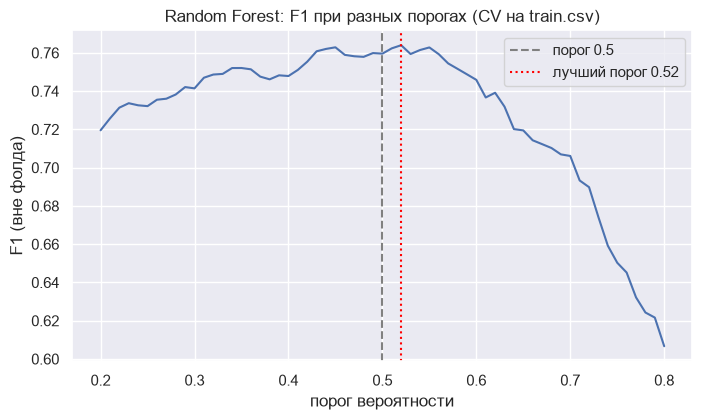

F1 при пороге 0.5: 0.7596, при лучшем пороге 0.52: 0.7640 (выигрыш 0.0044)
Разброс F1 между фолдами (std): 0.0520
Выбранный порог: 0.5


In [ ]:
best_k_model = kaggle_models[kaggle_best]
assert hasattr(best_k_model, "predict_proba"), "для подбора порога нужна модель, которая выдаёт вероятности"
oof_proba = cross_val_predict(best_k_model, Xk, yk, cv=cv, method="predict_proba")[:, 1]  # вероятности "вне фолда"

thresholds = np.round(np.linspace(0.20, 0.80, 61), 2)  # от 0.20 до 0.80 с шагом 0.01
f1_by_thr = pd.Series([f1_score(yk, (oof_proba >= t).astype(int)) for t in thresholds], index=thresholds)
best_thr = f1_by_thr.idxmax()
gain = f1_by_thr.max() - f1_by_thr[0.5]
noise_k = kaggle_cv.loc[kaggle_best, "CV F1 std"]
THRESHOLD = best_thr if gain > noise_k else 0.5

plt.figure(figsize=(8, 4.3))
plt.plot(f1_by_thr.index, f1_by_thr.values)
plt.axvline(0.5, color="gray", linestyle="--", label="порог 0.5")
plt.axvline(best_thr, color="red", linestyle=":", label=f"лучший порог {best_thr}")
plt.xlabel("порог вероятности")
plt.ylabel("F1 (вне фолда)")
plt.title(f"{kaggle_best}: F1 при разных порогах (CV на train.csv)")
plt.legend()
plt.show()

print(f"F1 при пороге 0.5: {f1_by_thr[0.5]:.4f}, при лучшем пороге {best_thr}: {f1_by_thr.max():.4f} (выигрыш {gain:.4f})")
print(f"Разброс F1 между фолдами (std): {noise_k:.4f}")
print(f"Выбранный порог: {THRESHOLD}")

**Вывод:**
- Кривая почти плоская: при пороге от 0.43 до 0.56 F1 держится около 0.76. Лучший порог 0.52 даёт всего +0.004 к порогу 0.5, а результаты от фолда к фолду скачут на 0.052.
- По правилу оставляем порог **0.5**: такой выигрыш - случайность, и на новых данных его, скорее всего, не будет.
- Сильно сдвигать порог вредно: при 0.2 модель "спасает" слишком многих, при 0.8 - почти никого, и F1 падает.

### 19.4. Обучение на всех 891 пассажирах и файл для отправки

In [ ]:
final_kaggle = clone(best_k_model).fit(Xk, yk)  # выбранная модель с теми же параметрами, обученная на всём train.csv
test_proba = final_kaggle.predict_proba(Xk_test)[:, 1]
submission = pd.DataFrame({"Id": k_test["Id"], "Survived": (test_proba >= THRESHOLD).astype(int)})

# проверки формата посылки из правил соревнования
assert list(submission.columns) == ["Id", "Survived"]
assert len(submission) == len(k_sample) == 1000
assert (submission["Id"].values == k_sample["Id"].values).all() and submission["Id"].is_unique
assert submission["Survived"].isin([0, 1]).all()

SUBMISSION_PATH = Path("submission.csv")
submission.to_csv(SUBMISSION_PATH, index=False)
print(f"Сохранено: {SUBMISSION_PATH}, строк: {len(submission)}")
print(f"Доля ответов 'выжил': в посылке {submission['Survived'].mean():.1%}, в train.csv {yk.mean():.1%}")
submission.head()

Сохранено: submission.csv, строк: 1000
Доля ответов 'выжил': в посылке 33.5%, в train.csv 38.4%


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0


**Вывод:**
- Файл `submission.csv` готов: 1000 строк, столбцы `Id,Survived`, все `Id` из шаблона в том же порядке, значения только 0 и 1 - всё по правилам соревнования.
- Модель отвечает "выжил" для 33.5% пассажиров test - чуть реже, чем доля выживших в train (38.4%). Это согласуется с разделом 16: лес чаще пропускает выживших, чем ошибочно "спасает" погибших.
- Ожидаемый результат на Kaggle - около 0.76, как на CV. Но тест синтетический, а публичная часть рейтинга - всего 300 объектов, поэтому реальное значение может отличаться на несколько сотых.

### 19.5. Методы и источники (по правилам соревнования)
- **Данные:** Titanic Dataset (Yasser H., Kaggle, лицензия CC0) - файлы `train.csv`, `test.csv` и `sample_submission.csv` из соревнования.
- **Модель:** Random Forest из scikit-learn (300 деревьев, в листе минимум 2 пассажира, `random_state=42`), порог 0.5. Предобработка в `Pipeline`: пропуски чисел - медианой, пропуски категорий - самым частым значением, категории - one-hot. Признаки: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` и `FamilySize`.
- **Выбор модели и порога:** 5-fold стратифицированная кросс-валидация на `train.csv`; `test.csv` использовался только для прогноза.
- **Библиотеки:** pandas, numpy, scikit-learn, matplotlib, seaborn.
- **Воспроизводимость:** весь код подготовки данных, обучения и формирования посылки - в этом ноутбуке (разделы 1, 6, 7 и 19). При повторном запуске получается тот же `submission.csv`.